# Customer Churn Prediction

## Final Project

The objective of this project is to build a machine learning model capable of predicting customer churn based on anonymized telecom customer data.

The model will be evaluated using the Balanced Accuracy metric.

# Exploratory Data Analysis (EDA)

Before building machine learning models, it is important to understand the structure and quality of the dataset.

In this section, we will:
- examine the dataset structure and feature types;
- analyze the target variable distribution;
- identify missing values;
- explore numerical and categorical features;
- inspect feature correlations.

The insights obtained during EDA will help determine the most appropriate preprocessing steps and modeling approach.

## Selected model

The selected submission is **submission_final_d5_threshold_030.csv**, with Kaggle Public Score **0.8977**. D5 uses balanced LightGBM, 212 non-empty input columns and 12 quartile flags, without correlated-column removal or separate missing indicators. Its threshold **0.30** was selected on the local validation split.

The analysis covers data exploration, classifier comparison, class balancing, tuning, feature selection, missingness features, error analysis and targeted feature engineering. Each experiment reports its own evaluation. D5 is the final submission; the other CSV files belong to comparison models.

Validation data informed several modeling decisions, so validation and threshold-selected OOF scores are development estimates. The submission fingerprint checks ordered predictions against a reference; it does not measure predictive quality.

In [1]:
!pip install catboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 8.1 MB/s eta 0:00:00


In [2]:
!pip install xgboost

In [3]:
%pip install lightgbm==4.6.0


In [4]:
!pip install -q optuna

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 442.4/442.4 kB 8.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 267.4/267.4 kB 9.6 MB/s eta 0:00:00


In [5]:
import time

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    train_test_split,
    cross_val_score,
    RandomizedSearchCV,
)

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.decomposition import TruncatedSVD

from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier,
    ExtraTreesClassifier,
    AdaBoostClassifier,
)

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
)

from lightgbm import LGBMClassifier
from xgboost import XGBClassifier
from catboost import CatBoostClassifier

from scipy.stats import randint, uniform

from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
from sklearn.metrics import confusion_matrix

from sklearn.base import clone, BaseEstimator, TransformerMixin

from google.colab import files

from sklearn.model_selection import cross_val_predict, StratifiedKFold

import optuna


from sklearn.utils.validation import check_is_fitted

import hashlib

In [6]:
# Record versions used for this execution.
import sys
from importlib.metadata import version

print("Python:", sys.version)
for package in ["numpy", "pandas", "scipy", "scikit-learn", "lightgbm",
                "imbalanced-learn", "catboost", "xgboost", "optuna"]:
    print(f"{package}=={version(package)}")


Python: 3.13.15 (main, Aug  6 2026, 11:06:23) [GCC 11.4.0]
numpy==2.1.3
pandas==2.2.3
scipy==1.16.3
scikit-learn==1.6.1
lightgbm==4.6.0
imbalanced-learn==0.14.2
catboost==1.2.10
xgboost==3.4.1
optuna==5.0.0


In [7]:
urls = {
    "train": "https://raw.githubusercontent.com/goitacademy/MACHINE-LEARNING-NEO/main/competition/final_proj_data.csv",
    "test": "https://raw.githubusercontent.com/goitacademy/MACHINE-LEARNING-NEO/main/competition/final_proj_test.csv",
    "sample": "https://raw.githubusercontent.com/goitacademy/MACHINE-LEARNING-NEO/main/competition/final_proj_sample_submission.csv",
}

train = pd.read_csv(urls["train"])
test = pd.read_csv(urls["test"])
sample_submission = pd.read_csv(urls["sample"])

In [8]:
print(train.shape)
print(test.shape)
print(sample_submission.shape)

(10000, 231)
(2500, 230)
(2500, 2)


In [9]:
train.head()

,Var1,Var2,Var3,Var4,Var5,Var6,Var7,Var8,Var9,Var10,...,Var222,Var223,Var224,Var225,Var226,Var227,Var228,Var229,Var230,y
0,NaN,NaN,NaN,NaN,NaN,812.0,14.0,NaN,NaN,NaN,...,catzS2D,jySVZNlOJy,NaN,xG3x,Aoh3,ZI9m,ib5G6X1eUxUn6,mj86,NaN,0
1,NaN,NaN,NaN,NaN,NaN,2688.0,7.0,NaN,NaN,NaN,...,i06ocsg,LM8l689qOp,NaN,kG3k,WqMG,RAYp,55YFVY9,mj86,NaN,0
2,NaN,NaN,NaN,NaN,NaN,1015.0,14.0,NaN,NaN,NaN,...,P6pu4Vl,LM8l689qOp,NaN,kG3k,Aoh3,ZI9m,R4y5gQQWY8OodqDV,am7c,NaN,0
3,NaN,NaN,NaN,NaN,NaN,168.0,0.0,NaN,NaN,NaN,...,BNrD3Yd,LM8l689qOp,NaN,NaN,FSa2,RAYp,F2FyR07IdsN7I,NaN,NaN,0
4,NaN,NaN,NaN,NaN,NaN,14.0,0.0,NaN,NaN,NaN,...,3B1QowC,LM8l689qOp,NaN,NaN,WqMG,RAYp,F2FyR07IdsN7I,NaN,NaN,0


In [10]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Columns: 231 entries, Var1 to y
dtypes: float64(191), int64(2), object(38)
memory usage: 17.6+ MB


In [11]:
train.describe()

,Var1,Var2,Var3,Var4,Var5,Var6,Var7,Var8,Var9,Var10,...,Var184,Var185,Var186,Var187,Var188,Var189,Var190,Var209,Var230,y
count,133.000000,266.0,266.000000,280.000000,2.410000e+02,8980.000000,8995.000000,0.0,133.000000,2.410000e+02,...,266.000000,0.0,133.000000,133.000000,266.000000,4206.000000,43.000000,0.0,0.0,10000.00000
mean,14.977444,0.0,341.052632,0.096429,2.338101e+05,1340.916258,6.860700,NaN,61.383459,3.672943e+05,...,6.180451,NaN,2.977444,20.601504,159.107368,272.455064,25725.112326,NaN,NaN,0.13050
std,66.456008,0.0,2810.606975,0.928243,5.532305e+05,2380.516758,6.300994,NaN,266.124849,8.234215e+05,...,12.177204,NaN,10.329764,93.736247,115.766972,86.752531,37487.484852,NaN,NaN,0.33687
min,0.000000,0.0,0.000000,0.000000,0.000000e+00,0.000000,0.000000,NaN,0.000000,0.000000e+00,...,0.000000,NaN,0.000000,0.000000,0.000000,6.000000,0.000000,NaN,NaN,0.00000
25%,0.000000,0.0,0.000000,0.000000,0.000000e+00,523.250000,0.000000,NaN,2.000000,0.000000e+00,...,0.000000,NaN,0.000000,0.000000,18.840000,204.000000,1312.875000,NaN,NaN,0.00000
50%,0.000000,0.0,0.000000,0.000000,0.000000e+00,861.000000,7.000000,NaN,18.000000,0.000000e+00,...,0.000000,NaN,0.000000,4.000000,194.670000,270.000000,10853.820000,NaN,NaN,0.00000
75%,16.000000,0.0,0.000000,0.000000,1.172350e+05,1428.000000,7.000000,NaN,40.000000,2.439360e+05,...,7.000000,NaN,0.000000,12.000000,247.080000,330.000000,37491.525000,NaN,NaN,0.00000
max,680.000000,0.0,42588.000000,9.000000,3.024000e+06,76195.000000,35.000000,NaN,2300.000000,6.394806e+06,...,64.000000,NaN,102.000000,878.000000,452.760000,642.000000,191167.200000,NaN,NaN,1.00000


In [12]:
train.describe(include="object")

,Var191,Var192,Var193,Var194,Var195,Var196,Var197,Var198,Var199,Var200,...,Var220,Var221,Var222,Var223,Var224,Var225,Var226,Var227,Var228,Var229
count,170,9921,10000,2533,10000,10000,9972,10000,10000,5043,...,10000,10000,10000,8987,167,4891,10000,10000,10000,4439
unique,1,297,40,3,18,3,185,2100,1850,4478,...,2100,7,2100,4,1,3,23,7,29,4
top,r__I,8I1r4RXXnK,RO12,SEuy,taul,1K8T,0Xwj,fhk21Ss,r83_sZi,yP09M03,...,4UxGlow,oslk,catzS2D,LM8l689qOp,4n2X,ELof,FSa2,RAYp,F2FyR07IdsN7I,am7c
freq,170,92,6965,2491,9606,9908,929,956,213,16,...,956,7200,956,7322,167,2358,1531,6790,6253,2388


In [13]:
train["y"].value_counts()

,count
y,
0,8695
1,1305


In [14]:
train.isna().sum().sort_values(ascending=False)

,0
Var20,10000
Var39,10000
Var32,10000
Var31,10000
Var8,10000
...,...
Var216,0
Var227,0
Var226,0
Var228,0


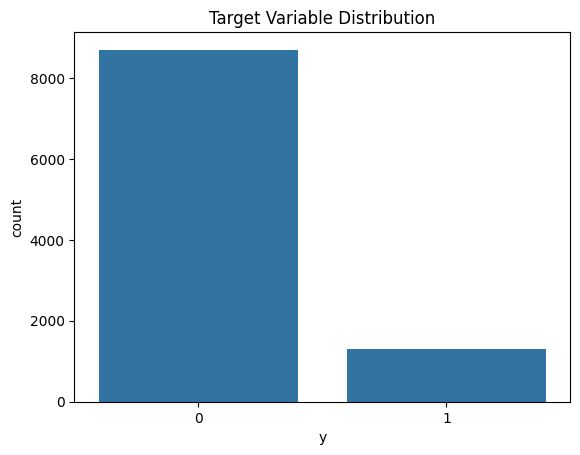

In [15]:
sns.countplot(data=train, x="y")
plt.title("Target Variable Distribution")
plt.show()

In [16]:
missing = (
    train.isna().mean() * 100
).sort_values(ascending=False)

missing[missing > 0]

,0
Var20,100.00
Var39,100.00
Var32,100.00
Var31,100.00
Var8,100.00
...,...
Var217,1.28
Var192,0.79
Var197,0.28
Var203,0.28


In [17]:
train.dtypes.value_counts()

,count
float64,191
object,38
int64,2


In [18]:
categorical_cols = train.select_dtypes(include="object").columns

train[categorical_cols].nunique().sort_values(ascending=False)

,0
Var217,5529
Var200,4478
Var214,4478
Var202,3802
Var220,2100
Var222,2100
Var198,2100
Var199,1850
Var216,977
Var192,297


In [19]:
corr = train.corr(numeric_only=True)["y"].sort_values()

feature_corr = corr.drop(labels="y").dropna()
display(feature_corr.tail(10))
display(feature_corr.head(10))


,y
Var126,0.081730
Var111,0.082472
Var113,0.089439
Var117,0.090627
Var19,0.097407
Var81,0.102741
Var46,0.112020
Var139,0.113661
Var135,0.117693
Var130,0.133732


,y
Var189,-0.243347
Var73,-0.231347
Var7,-0.189391
Var180,-0.172063
Var168,-0.155667
Var154,-0.154859
Var147,-0.152392
Var172,-0.137059
Var190,-0.136471
Var65,-0.132815


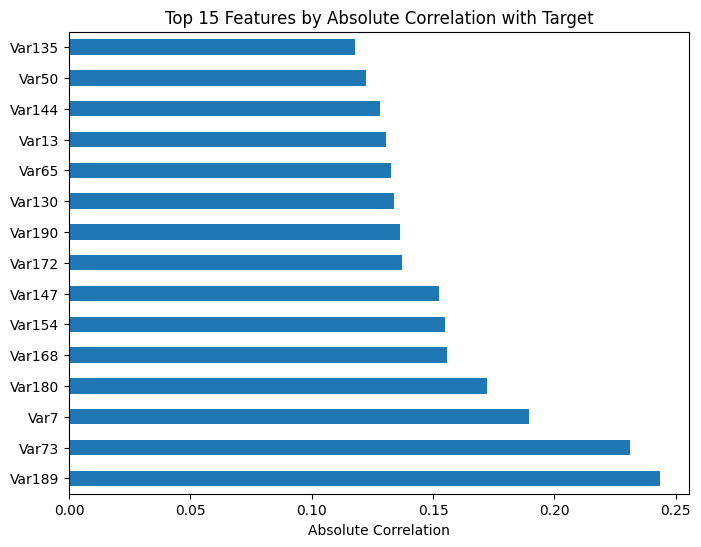

In [20]:
top_corr = corr.drop("y").abs().sort_values(ascending=False).head(15)

plt.figure(figsize=(8,6))
top_corr.plot(kind="barh")
plt.title("Top 15 Features by Absolute Correlation with Target")
plt.xlabel("Absolute Correlation")
plt.show()

# Exploratory Data Analysis Summary

The exploratory data analysis provided an initial understanding of the dataset and its overall structure.

The main findings are summarized below:

- The training dataset contains **10,000 observations** and **231 columns**, while the test dataset contains **2,500 observations** and **230 columns**. The target variable `y` is available only in the training dataset.
- The dataset includes both **numerical** and **categorical** features. Most variables are numerical, while the remaining features are stored as categorical (`object`) data type.
- A considerable number of features contain missing values, with some variables having a very high percentage of missing data. Therefore, handling missing values will be one of the key preprocessing steps.
- The target variable is **imbalanced**, which justifies the use of **Balanced Accuracy** as the evaluation metric and suggests that class balancing techniques may be explored during model development.
- Numerical features have different value ranges and distributions. Depending on the selected machine learning algorithm, feature scaling may be required.
- Categorical features contain different numbers of unique categories, which should be considered when selecting an appropriate encoding method.
- Correlation analysis shows that several numerical features have a moderate relationship with the target variable, while most features exhibit relatively weak individual correlations. This suggests that model performance will likely depend on combining information from multiple features rather than relying on a small number of highly correlated variables.

Overall, the dataset is suitable for a supervised binary classification task. However, careful preprocessing, appropriate feature engineering, and model selection will be essential for achieving good predictive performance.

# Data Preprocessing

After completing the exploratory data analysis, the dataset is prepared for model training.

In this section, we will:
- separate the target variable from the input features;
- identify numerical and categorical features;
- split the data into training and validation sets;
- build preprocessing pipelines for numerical and categorical features;
- apply appropriate transformations before training machine learning models.

In [21]:
X = train.drop(columns="y")
y = train["y"]

### Train-Validation Split

To evaluate model performance objectively, the dataset is divided into training and validation subsets.

A stratified split is used to preserve the original class distribution in both subsets, ensuring a reliable evaluation of the classification model.

In [22]:
X_train, X_valid, y_train, y_valid = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [23]:
print(X_train.shape)
print(X_valid.shape)
print(y_train.shape)
print(y_valid.shape)

(8000, 230)
(2000, 230)
(8000,)
(2000,)


### Removing Empty Features

Some features contain only missing values in the training data and therefore do not provide any useful information for the model.

These columns will be removed from the training, validation, and test datasets before model training to simplify the preprocessing pipeline and eliminate unnecessary warnings.

In [24]:
all_nan_columns = X_train.columns[X_train.isna().all()]

print(all_nan_columns)

Index(['Var8', 'Var15', 'Var20', 'Var31', 'Var32', 'Var39', 'Var42', 'Var48',
       'Var52', 'Var55', 'Var79', 'Var141', 'Var167', 'Var169', 'Var175',
       'Var185', 'Var209', 'Var230'],
      dtype='object')


In [25]:
X_train = X_train.drop(columns=all_nan_columns)
X_valid = X_valid.drop(columns=all_nan_columns)
test = test.drop(columns=all_nan_columns)

### Feature Identification


In [26]:
numeric_features = X_train.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X_train.select_dtypes(include=["object"]).columns.tolist()

In [27]:
print(f"Numerical features: {len(numeric_features)}")
print(f"Categorical features: {len(categorical_features)}")

Numerical features: 174
Categorical features: 38


The numerical and categorical features were identified automatically based on their data types and will be used for the preprocessing pipeline.

## Preprocessing Pipeline

To ensure consistent data preparation and prevent data leakage, preprocessing steps will be combined into a single machine learning pipeline.

Separate transformations will be applied to numerical and categorical features before training the classification models.

In [28]:
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

In [29]:
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore"
    ))
])

In [30]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

# Baseline Model: Logistic Regression

To establish a baseline for model performance, a Logistic Regression classifier will be trained using the preprocessing pipeline created in the previous step.

This baseline model will provide a reference point for evaluating more advanced ensemble methods, such as Random Forest and Gradient Boosting, later in the project.

In [31]:
numeric_transformer_lr = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

preprocessor_lr = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer_lr, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

In [32]:
baseline_model = Pipeline(steps=[
    ("preprocessor", preprocessor_lr),
    ("classifier", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

In [33]:
baseline_model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['Var1', 'Var2', 'Var3',
                                                   'Var4', 'Var5', 'Var6',
                                                   'Var7', 'Var9', 'Var10',
                                                   'Var11', 'Var12', 'Var13',
                                                   'Var14', 'Var16', 'Var17',
                                                   'Var18', 'Var19', 'Var21',
                                                   'Var22', 'Var23', 'Var24',
                                                   'Var25', 'Var26', 'Var27',
                                                   'Va...
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['Var191', 'Var192', 'Var193',
                                                   'Var194', 'Var195', 'Var196',
                                                   'Var197', 'Var198', 'Var199',
                                                   'Var200', 'Var201', 'Var202',
                                                   'Var203', 'Var204', 'Var205',
                                                   'Var206', 'Var207', 'Var208',
                                                   'Var210', 'Var211', 'Var212',
                                                   'Var213', 'Var214', 'Var215',
                                                   'Var216', 'Var217', 'Var218',
                                                   'Var219', 'Var220', 'Var221', ...])])),
                ('classifier',
                 LogisticRegression(max_iter=1000, random_state=42))])

In [34]:
y_pred = baseline_model.predict(X_valid)

In [35]:
baseline_score = balanced_accuracy_score(y_valid, y_pred)

print(f"Baseline Balanced Accuracy: {baseline_score:.4f}")

Baseline Balanced Accuracy: 0.6739


# Ensemble Models Comparison

To improve predictive performance, several ensemble learning algorithms are evaluated using the same preprocessing pipeline.

Each model is trained and evaluated on the validation dataset using the Balanced Accuracy metric. The results are compared to identify the most promising candidate for further hyperparameter tuning.

In [36]:
models = {
    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    ),

    "Extra Trees": ExtraTreesClassifier(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    ),

    "AdaBoost": AdaBoostClassifier(
        n_estimators=200,
        random_state=42
    ),

    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=200,
        learning_rate=0.05,
        random_state=42
    ),

    "XGBoost": XGBClassifier(
        random_state=42,
        eval_metric="logloss"
    ),

    "LightGBM": LGBMClassifier(
        random_state=42,
        verbose=-1
    ),

    "CatBoost": CatBoostClassifier(
        random_state=42,
        verbose=0
    )
}

In [37]:
results = []

for name, model in models.items():
    print(f"Training: {name}")

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", model)
    ])

    start = time.time()
    pipeline.fit(X_train, y_train)
    train_time = time.time() - start

    start = time.time()
    y_pred = pipeline.predict(X_valid)
    predict_time = time.time() - start

    score = balanced_accuracy_score(y_valid, y_pred)

    results.append({
        "Model": name,
        "Balanced Accuracy": score,
        "Training Time (s)": train_time,
        "Prediction Time (s)": predict_time
    })

    print(f"Finished: {name} | Score: {score:.4f}")

Training: Random Forest
Finished: Random Forest | Score: 0.5287
Training: Extra Trees
Finished: Extra Trees | Score: 0.5541
Training: AdaBoost
Finished: AdaBoost | Score: 0.7193
Training: Gradient Boosting
Finished: Gradient Boosting | Score: 0.7041
Training: XGBoost
Finished: XGBoost | Score: 0.7792
Training: LightGBM


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


Finished: LightGBM | Score: 0.7929
Training: CatBoost
Finished: CatBoost | Score: 0.7375


In [38]:
results_df = pd.DataFrame(results)
display(results_df.sort_values(
    "Balanced Accuracy",
    ascending=False
))

,Model,Balanced Accuracy,Training Time (s),Prediction Time (s)
5,LightGBM,0.792906,1.341409,0.154325
4,XGBoost,0.779209,5.184236,0.129210
6,CatBoost,0.737545,103.679756,0.149780
2,AdaBoost,0.719344,48.958594,1.125545
3,Gradient Boosting,0.704115,65.035672,0.113157
1,Extra Trees,0.554118,21.952347,0.316694
0,Random Forest,0.528736,28.437828,0.276771


### Model Comparison Summary

Several machine learning models were trained and evaluated using the same training and validation split. Model performance was assessed using the Balanced Accuracy metric to account for the class imbalance in the target variable.

Among all evaluated models, **LightGBM** achieved the highest Balanced Accuracy (**0.7929**) while also demonstrating the shortest training time. **XGBoost** showed competitive performance with a Balanced Accuracy of **0.7792**, followed by **CatBoost** (**0.7375**). Traditional ensemble methods, including AdaBoost and Gradient Boosting, achieved lower scores, while Random Forest and Extra Trees showed the weakest performance on this dataset.

Based on these results, **LightGBM** was selected as the most promising model for further hyperparameter tuning and optimization in the next stage of the project.

In [39]:
best_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LGBMClassifier(
        random_state=42,
        verbose=-1
    ))
])

best_model.fit(X_train, y_train)

y_pred = best_model.predict(X_valid)

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


# Evaluation of the selected LightGBM model

In [40]:

print(f"Accuracy:          {accuracy_score(y_valid, y_pred):.4f}")
print(f"Balanced Accuracy: {balanced_accuracy_score(y_valid, y_pred):.4f}")
print(f"Precision:         {precision_score(y_valid, y_pred):.4f}")
print(f"Recall:            {recall_score(y_valid, y_pred):.4f}")
print(f"F1-score:          {f1_score(y_valid, y_pred):.4f}")

Accuracy:          0.9315
Balanced Accuracy: 0.7929
Precision:         0.8229
Recall:            0.6054
F1-score:          0.6976


## Dimensionality Reduction (TruncatedSVD)

Before proceeding to hyperparameter optimization, an additional experiment is conducted to evaluate whether reducing the dimensionality of the dataset can improve the predictive performance of the selected model. The performance of LightGBM trained on the transformed feature space will be compared with the baseline LightGBM model.

In [41]:
svd_model = Pipeline([
    ("preprocessor", preprocessor),
    ("svd", TruncatedSVD(n_components=50, random_state=42)),
    ("classifier", LGBMClassifier(
        random_state=42,
        verbose=-1
    ))
])

svd_model.fit(X_train, y_train)

y_pred_svd = svd_model.predict(X_valid)

print(
    "Balanced Accuracy with dimensionality reduction:",
    balanced_accuracy_score(y_valid, y_pred_svd)
)

Balanced Accuracy with dimensionality reduction: 0.5090001960875035


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


## Conclusion
Dimensionality reduction using TruncatedSVD was evaluated as an alternative to the original feature space. The obtained Balanced Accuracy (0.5090) was significantly lower than the result achieved without dimensionality reduction (0.7929). Therefore, dimensionality reduction was not used in the final model.

## Cross Validation

To obtain a more reliable estimate of the selected LightGBM model performance, cross-validation is performed using Balanced Accuracy as the evaluation metric.

This allows the model to be evaluated on several different train-validation splits instead of relying on a single validation set.

In [42]:
cv_scores = cross_val_score(
    best_model,
    X,
    y,
    cv=5,
    scoring="balanced_accuracy"
)

print("Cross-validation scores:", cv_scores)
print(f"Mean Balanced Accuracy: {cv_scores.mean():.4f}")
print(f"Standard deviation: {cv_scores.std():.4f}")

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


Cross-validation scores: [0.80420663 0.79165923 0.81886362 0.78552764 0.80124108]
Mean Balanced Accuracy: 0.8003
Standard deviation: 0.0114


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


### Conclusion

The selected LightGBM model was evaluated using 5-fold cross-validation.

The average Balanced Accuracy was **0.8003** with a standard deviation of **0.0114**, indicating stable performance across different train-validation splits.

Therefore, the selected model demonstrates good generalization ability and is suitable for further hyperparameter optimization.

## Hyperparameter Optimization

To further improve the predictive performance of the selected LightGBM model, hyperparameter optimization is performed using RandomizedSearchCV.

Different combinations of the most important LightGBM hyperparameters are evaluated, and the configuration with the highest Balanced Accuracy is selected.

In [43]:
param_dist = {
    "classifier__n_estimators": randint(100, 500),
    "classifier__learning_rate": uniform(0.01, 0.2),
    "classifier__num_leaves": randint(20, 100),
    "classifier__max_depth": randint(3, 15),
    "classifier__subsample": uniform(0.6, 0.4),
    "classifier__colsample_bytree": uniform(0.6, 0.4),
}

random_search = RandomizedSearchCV(
    estimator=best_model,
    param_distributions=param_dist,
    n_iter=100,
    scoring="balanced_accuracy",
    cv=5,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

random_search.fit(X_train, y_train)

Fitting 5 folds for each of 100 candidates, totalling 500 fits


RandomizedSearchCV(cv=5,
                   estimator=Pipeline(steps=[('preprocessor',
                                              ColumnTransformer(transformers=[('num',
                                                                               Pipeline(steps=[('imputer',
                                                                                                SimpleImputer(strategy='median'))]),
                                                                               ['Var1',
                                                                                'Var2',
                                                                                'Var3',
                                                                                'Var4',
                                                                                'Var5',
                                                                                'Var6',
                                                                                'Var7',
                                                                                'Var9',
                                                                                'Var10',
                                                                                'Var11',
                                                                                'Var12',
                                                                                'Var13',
                                                                                'Var14',
                                                                                'Var16',
                                                                                'Var17',
                                                                                'Var18',
                                                                                'Var19',
                                                                                'Var21',
                                                                                'Var22',
                                                                                'Var23',
                                                                                'Var24',
                                                                                'Var25',
                                                                                'Var26',
                                                                                'Var2...
                                        'classifier__n_estimators': <scipy.stats._distn_infrastructure.rv_discrete_frozen object at 0x7e9d07ff3e00>,
                                        'classifier__num_leaves': <scipy.stats._distn_infrastructure.rv_discrete_frozen object at 0x7e9d05850550>,
                                        'classifier__subsample': <scipy.stats._distn_infrastructure.rv_continuous_frozen object at 0x7e9d05850a50>},
                   random_state=42, scoring='balanced_accuracy', verbose=1)

In [44]:
print("Best parameters:")
print(random_search.best_params_)

print(f"\nBest Balanced Accuracy: {random_search.best_score_:.4f}")

Best parameters:
{'classifier__colsample_bytree': np.float64(0.8473544037332349), 'classifier__learning_rate': np.float64(0.08649239825343255), 'classifier__max_depth': 6, 'classifier__n_estimators': 419, 'classifier__num_leaves': 22, 'classifier__subsample': np.float64(0.9439761626945282)}

Best Balanced Accuracy: 0.7835


### Hyperparameter optimization results

RandomizedSearchCV achieved a best cross-validation Balanced Accuracy of **0.7835** on the training subset. The earlier default-model CV score of **0.8003** was calculated on the full labeled dataset, so the two scores are not a controlled comparison using identical folds. The default configuration was retained for the subsequent class-balancing experiments; these results alone do not establish that tuning is ineffective.

This search varied `subsample` while `subsample_freq` remained 0, so row subsampling was inactive. The balanced and Optuna searches use `subsample_freq=1`.


## Class imbalance analysis

The next experiments investigate whether accounting for the observed class imbalance improves LightGBM performance. SMOTE and class weighting are compared on the same training-validation split.


In [45]:
print(y.value_counts())
print()
print(y.value_counts(normalize=True))

y
0    8695
1    1305
Name: count, dtype: int64

y
0    0.8695
1    0.1305
Name: proportion, dtype: float64


## Class balancing with SMOTE

The target variable is imbalanced (approximately 87% of observations belong to class 0 and 13% to class 1). To evaluate whether class imbalance affects the predictive performance of the model, the training data is balanced using the SMOTE technique. The results are then compared with the baseline LightGBM model.

In [46]:
smote_model = ImbPipeline([
    ("preprocessor", preprocessor),
    ("smote", SMOTE(random_state=42)),
    ("classifier", LGBMClassifier(
        random_state=42,
        verbose=-1
    ))
])

smote_model.fit(X_train, y_train)

y_pred_smote = smote_model.predict(X_valid)

print("Balanced Accuracy with SMOTE:",
      balanced_accuracy_score(y_valid, y_pred_smote))

Balanced Accuracy with SMOTE: 0.8032504257742703


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


### SMOTE results

Applying SMOTE slightly improved the validation Balanced Accuracy from **0.7929** to **0.8033**.

This experiment has limitations: SMOTE was applied after one-hot encoding and without scaling the numerical features. Interpolation can produce fractional values in encoded categorical columns, while differences in numerical scales affect neighbor distances. These results therefore describe this specific preprocessing configuration, rather than establishing the general effectiveness of SMOTE for this dataset.

The final model uses `class_weight="balanced"` and does not use SMOTE.


### Class balancing with class_weight

As an alternative to SMOTE, the built-in `class_weight="balanced"` option of LightGBM is evaluated. This approach automatically assigns higher importance to the minority class without generating synthetic samples.

In [47]:
weighted_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LGBMClassifier(
        class_weight="balanced",
        random_state=42,
        verbose=-1
    ))
])

weighted_model.fit(X_train, y_train)

y_pred_weighted = weighted_model.predict(X_valid)

print(
    "Balanced Accuracy with class_weight:",
    balanced_accuracy_score(y_valid, y_pred_weighted)
)

Balanced Accuracy with class_weight: 0.8592675580936769


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


### Class balancing results

On the same validation set, using `class_weight="balanced"` improved the Balanced Accuracy from **0.7929** to **0.8593** and outperformed SMOTE (**0.8033**). Therefore, this approach was selected for the following experiments.

In [48]:
weighted_cv_scores = cross_val_score(
    weighted_model,
    X,
    y,
    cv=5,
    scoring="balanced_accuracy"
)

print("Cross-validation scores:", weighted_cv_scores)
print(f"Mean Balanced Accuracy: {weighted_cv_scores.mean():.4f}")
print(f"Standard deviation: {weighted_cv_scores.std():.4f}")

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


Cross-validation scores: [0.87344314 0.85332985 0.89585991 0.84748248 0.86856189]
Mean Balanced Accuracy: 0.8677
Standard deviation: 0.0170


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


### Cross-validation of the balanced model

The LightGBM model with `class_weight="balanced"` achieved a mean cross-validation Balanced Accuracy of **0.8677**, compared with **0.8003** for the unbalanced model. Therefore, the balanced model was selected for further experiments at this stage.

## Hyperparameter optimization of the balanced model

Since class weighting significantly improved the model performance, RandomizedSearchCV is applied to optimize the hyperparameters of the balanced LightGBM model.

In [49]:
weighted_param_dist = {
    "classifier__n_estimators": randint(150, 600),
    "classifier__learning_rate": uniform(0.02, 0.13),
    "classifier__num_leaves": randint(15, 80),
    "classifier__max_depth": randint(4, 16),
    "classifier__min_child_samples": randint(10, 80),
    "classifier__subsample": uniform(0.7, 0.3),
    "classifier__subsample_freq": [1],
    "classifier__colsample_bytree": uniform(0.7, 0.3),
    "classifier__reg_alpha": uniform(0, 5),
    "classifier__reg_lambda": uniform(0, 10),
}

weighted_search = RandomizedSearchCV(
    estimator=weighted_model,
    param_distributions=weighted_param_dist,
    n_iter=60,
    scoring="balanced_accuracy",
    cv=5,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

weighted_search.fit(X_train, y_train)

Fitting 5 folds for each of 60 candidates, totalling 300 fits


RandomizedSearchCV(cv=5,
                   estimator=Pipeline(steps=[('preprocessor',
                                              ColumnTransformer(transformers=[('num',
                                                                               Pipeline(steps=[('imputer',
                                                                                                SimpleImputer(strategy='median'))]),
                                                                               ['Var1',
                                                                                'Var2',
                                                                                'Var3',
                                                                                'Var4',
                                                                                'Var5',
                                                                                'Var6',
                                                                                'Var7',
                                                                                'Var9',
                                                                                'Var10',
                                                                                'Var11',
                                                                                'Var12',
                                                                                'Var13',
                                                                                'Var14',
                                                                                'Var16',
                                                                                'Var17',
                                                                                'Var18',
                                                                                'Var19',
                                                                                'Var21',
                                                                                'Var22',
                                                                                'Var23',
                                                                                'Var24',
                                                                                'Var25',
                                                                                'Var26',
                                                                                'Var2...
                                        'classifier__reg_alpha': <scipy.stats._distn_infrastructure.rv_continuous_frozen object at 0x7e9d07e7d6a0>,
                                        'classifier__reg_lambda': <scipy.stats._distn_infrastructure.rv_continuous_frozen object at 0x7e9d07e7dbf0>,
                                        'classifier__subsample': <scipy.stats._distn_infrastructure.rv_continuous_frozen object at 0x7e9d07e9a8b0>,
                                        'classifier__subsample_freq': [1]},
                   random_state=42, scoring='balanced_accuracy', verbose=1)

In [50]:
print("Best parameters:")
print(weighted_search.best_params_)

print(
    f"\nBest cross-validation Balanced Accuracy: "
    f"{weighted_search.best_score_:.4f}"
)

tuned_weighted_model = weighted_search.best_estimator_
y_pred_tuned = tuned_weighted_model.predict(X_valid)

tuned_validation_score = balanced_accuracy_score(
    y_valid,
    y_pred_tuned
)

print(
    f"Validation Balanced Accuracy: "
    f"{tuned_validation_score:.4f}"
)

Best parameters:
{'classifier__colsample_bytree': np.float64(0.89558837785078), 'classifier__learning_rate': np.float64(0.04915501022987277), 'classifier__max_depth': 4, 'classifier__min_child_samples': 77, 'classifier__n_estimators': 438, 'classifier__num_leaves': 28, 'classifier__reg_alpha': np.float64(1.6269984907963386), 'classifier__reg_lambda': np.float64(7.464914051180242), 'classifier__subsample': np.float64(0.8948898697141643), 'classifier__subsample_freq': 1}

Best cross-validation Balanced Accuracy: 0.8781
Validation Balanced Accuracy: 0.8912


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


In [51]:
print(f"Accuracy:          {accuracy_score(y_valid, y_pred_tuned):.4f}")
print(f"Balanced Accuracy: {balanced_accuracy_score(y_valid, y_pred_tuned):.4f}")
print(f"Precision:         {precision_score(y_valid, y_pred_tuned):.4f}")
print(f"Recall:            {recall_score(y_valid, y_pred_tuned):.4f}")
print(f"F1-score:          {f1_score(y_valid, y_pred_tuned):.4f}")

Accuracy:          0.8845
Balanced Accuracy: 0.8912
Precision:         0.5341
Recall:            0.9004
F1-score:          0.6705


### Hyperparameter optimization results

RandomizedSearchCV improved the balanced LightGBM model. The tuned model achieved a cross-validation Balanced Accuracy of **0.8781** and a validation Balanced Accuracy of **0.8912**, compared with **0.8593** for the balanced model with default parameters. Therefore, the tuned balanced LightGBM model was selected for further experiments at this stage.

## Removing Features with Many Missing Values

To evaluate whether highly incomplete features negatively affect model performance, columns with more than **35% missing values** in the training data are removed. The tuned balanced LightGBM model is then retrained and evaluated on the same validation set.

In [52]:
missing_ratio_35 = X_train.isna().mean()

columns_to_drop_35 = missing_ratio_35[
    missing_ratio_35 > 0.35
].index.tolist()

print("Columns removed:", len(columns_to_drop_35))

X_train_35 = X_train.drop(columns=columns_to_drop_35)
X_valid_35 = X_valid.drop(columns=columns_to_drop_35)

numeric_features_35 = (
    X_train_35.select_dtypes(include=["number"]).columns.tolist()
)

categorical_features_35 = (
    X_train_35.select_dtypes(include=["object"]).columns.tolist()
)

preprocessor_35 = ColumnTransformer([
    ("num", clone(numeric_transformer), numeric_features_35),
    ("cat", clone(categorical_transformer), categorical_features_35)
])

model_35 = Pipeline([
    ("preprocessor", preprocessor_35),
    (
        "classifier",
        clone(tuned_weighted_model.named_steps["classifier"])
    )
])

model_35.fit(X_train_35, y_train)
y_pred_35 = model_35.predict(X_valid_35)

print(f"Accuracy:          {accuracy_score(y_valid, y_pred_35):.4f}")
print(f"Balanced Accuracy: {balanced_accuracy_score(y_valid, y_pred_35):.4f}")
print(f"Precision:         {precision_score(y_valid, y_pred_35):.4f}")
print(f"Recall:            {recall_score(y_valid, y_pred_35):.4f}")
print(f"F1-score:          {f1_score(y_valid, y_pred_35):.4f}")

Columns removed: 145
Accuracy:          0.8730
Balanced Accuracy: 0.8765
Precision:         0.5077
Recall:            0.8812
F1-score:          0.6443


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


### Missing-value feature removal results

Removing 145 features with more than **35% missing values** reduced the validation Balanced Accuracy from **0.8912** to **0.8765**. Therefore, these features were retained, as they still provide useful information for prediction.

## Bayesian Hyperparameter Optimization with Optuna

Optuna is used to perform a more efficient hyperparameter search for the balanced LightGBM model. Unlike random search, it uses the results of previous trials to select more promising parameter combinations. Model performance is evaluated using stratified 5-fold cross-validation and Balanced Accuracy.

In [53]:
optuna.logging.set_verbosity(optuna.logging.WARNING)

optuna_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

def objective(trial):
    max_depth = trial.suggest_int("max_depth", 4, 12)

    classifier = LGBMClassifier(
        class_weight="balanced",
        random_state=42,
        verbose=-1,
        n_jobs=1,
        n_estimators=trial.suggest_int(
            "n_estimators", 150, 700
        ),
        learning_rate=trial.suggest_float(
            "learning_rate", 0.01, 0.12, log=True
        ),
        max_depth=max_depth,
        num_leaves=trial.suggest_int(
            "num_leaves",
            8,
            min(80, 2 ** max_depth)
        ),
        min_child_samples=trial.suggest_int(
            "min_child_samples", 10, 120
        ),
        subsample=trial.suggest_float(
            "subsample", 0.7, 1.0
        ),
        subsample_freq=1,
        colsample_bytree=trial.suggest_float(
            "colsample_bytree", 0.7, 1.0
        ),
        reg_alpha=trial.suggest_float(
            "reg_alpha", 1e-4, 10.0, log=True
        ),
        reg_lambda=trial.suggest_float(
            "reg_lambda", 1e-4, 20.0, log=True
        )
    )

    model = Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("classifier", classifier)
    ])

    scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=optuna_cv,
        scoring="balanced_accuracy",
        n_jobs=-1
    )

    return scores.mean()

study = optuna.create_study(
    direction="maximize",
    sampler=optuna.samplers.TPESampler(seed=42)
)

study.optimize(
    objective,
    n_trials=50,
    show_progress_bar=True,
    gc_after_trial=True
)

print(f"Best Optuna CV score: {study.best_value:.4f}")
print("Best parameters:")
print(study.best_params)

  0%|          | 0/50 [00:00<?, ?it/s]

Best Optuna CV score: 0.8840
Best parameters:
{'max_depth': 4, 'n_estimators': 601, 'learning_rate': 0.015848142463524267, 'num_leaves': 12, 'min_child_samples': 54, 'subsample': 0.7452838634069349, 'colsample_bytree': 0.7067183104132625, 'reg_alpha': 0.00022183412952993514, 'reg_lambda': 1.1212809689870427}


In [54]:
optuna_classifier = LGBMClassifier(
    class_weight="balanced",
    random_state=42,
    verbose=-1,
    n_jobs=-1,
    subsample_freq=1,
    **study.best_params
)

optuna_model = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("classifier", optuna_classifier)
])

optuna_model.fit(X_train, y_train)
y_pred_optuna = optuna_model.predict(X_valid)

print(f"Accuracy:          {accuracy_score(y_valid, y_pred_optuna):.4f}")
print(f"Balanced Accuracy: {balanced_accuracy_score(y_valid, y_pred_optuna):.4f}")
print(f"Precision:         {precision_score(y_valid, y_pred_optuna):.4f}")
print(f"Recall:            {recall_score(y_valid, y_pred_optuna):.4f}")
print(f"F1-score:          {f1_score(y_valid, y_pred_optuna):.4f}")

Accuracy:          0.8615
Balanced Accuracy: 0.8927
Precision:         0.4841
Recall:            0.9349
F1-score:          0.6379


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


### Optuna optimization results

Optuna achieved a cross-validation Balanced Accuracy of **0.8840**. On the validation set, the optimized model achieved **0.8927**, slightly outperforming the RandomizedSearchCV model (**0.8912**). Therefore, the Optuna model was selected for an additional Kaggle evaluation.

### Analysis of highly correlated features

Highly correlated numerical features are analyzed to identify potentially redundant or closely related variables. Before modifying the feature set, pairs with a strong absolute correlation are examined.

In [55]:
corr_matrix = X_train[numeric_features].corr().abs()

upper_triangle = corr_matrix.where(
    np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)
)

high_corr_pairs = (
    upper_triangle.stack()
    .reset_index()
)

high_corr_pairs.columns = ["Feature 1", "Feature 2", "Correlation"]

high_corr_pairs = (
    high_corr_pairs[high_corr_pairs["Correlation"] > 0.95]
    .sort_values("Correlation", ascending=False)
)

print("Number of highly correlated pairs:", len(high_corr_pairs))

display(high_corr_pairs.head(30))

Number of highly correlated pairs: 82


,Feature 1,Feature 2,Correlation
555,Var21,Var22,1.000000
3029,Var128,Var145,1.000000
2280,Var88,Var145,1.000000
2278,Var88,Var128,1.000000
2344,Var91,Var148,1.000000
1825,Var66,Var156,1.000000
2579,Var104,Var105,1.000000
1911,Var71,Var148,1.000000
1899,Var71,Var91,1.000000
233,Var9,Var66,1.000000


In [56]:
display(high_corr_pairs)

,Feature 1,Feature 2,Correlation
555,Var21,Var22,1.000000
3029,Var128,Var145,1.000000
2280,Var88,Var145,1.000000
2278,Var88,Var128,1.000000
2344,Var91,Var148,1.000000
...,...,...,...
2286,Var88,Var164,0.955586
1817,Var66,Var121,0.955578
2892,Var121,Var156,0.955578
3181,Var145,Var164,0.954970


### Highly correlated features: findings

The analysis identified **82 pairs of numerical features** with an absolute correlation above **0.95** in the training subset. Several pairs had correlations approximately equal to **1.0**, indicating potentially redundant information.

These are **82 feature pairs, not 82 individual features**: the same feature may appear in multiple pairs. High correlation also does not necessarily mean that two columns contain identical values.

This analysis motivated separate feature-removal experiments using thresholds of **0.99** and **0.98**. No features were removed or combined in this analysis step; the effect of removal was evaluated separately through model performance.

### Removing highly correlated features

To investigate whether redundant numerical features affect model performance, features with an absolute correlation above **0.99** are identified. One feature from each highly correlated pair is removed in an experimental dataset, and the LightGBM model is evaluated again.

In [57]:
# Calculate correlations using training data only
corr_matrix = X_train[numeric_features].corr().abs()

upper_triangle = corr_matrix.where(
    np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)
)

# Select redundant features with correlation > 0.99
features_to_drop = [
    column for column in upper_triangle.columns
    if any(upper_triangle[column] > 0.99)
]

print("Number of features to remove:", len(features_to_drop))
print("Features:", features_to_drop)

Number of features to remove: 13
Features: ['Var22', 'Var66', 'Var77', 'Var91', 'Var99', 'Var105', 'Var127', 'Var128', 'Var129', 'Var145', 'Var148', 'Var156', 'Var174']


In [58]:
# Create datasets without highly correlated features
X_train_reduced = X_train.drop(columns=features_to_drop)
X_valid_reduced = X_valid.drop(columns=features_to_drop)

# Update feature lists
numeric_features_reduced = [
    col for col in numeric_features if col not in features_to_drop
]

categorical_features_reduced = [
    col for col in categorical_features if col not in features_to_drop
]

# Create preprocessing pipeline for the reduced dataset
preprocessor_reduced = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), numeric_features_reduced),
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ]), categorical_features_reduced)
])

# LightGBM with class balancing
reduced_model = Pipeline([
    ("preprocessor", preprocessor_reduced),
    ("classifier", LGBMClassifier(
        class_weight="balanced",
        random_state=42,
        verbose=-1
    ))
])

reduced_model.fit(X_train_reduced, y_train)

y_pred_reduced = reduced_model.predict(X_valid_reduced)

print(
    "Balanced Accuracy without highly correlated features:",
    balanced_accuracy_score(y_valid, y_pred_reduced)
)

Balanced Accuracy without highly correlated features: 0.8638645982739893


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


### Correlated feature removal results

Removing highly correlated features slightly improved the Balanced Accuracy from **0.8593** to **0.8639**. Therefore, the reduced feature set was retained for the final model.

In [59]:
# Separate experiment: correlation above 0.98
corr_098 = X_train[numeric_features].corr().abs()

upper_098 = corr_098.where(
    np.triu(np.ones(corr_098.shape), k=1).astype(bool)
)

features_to_drop_098 = [
    col for col in upper_098.columns
    if (upper_098[col] > 0.98).any()
]

print("Кількість ознак для видалення:", len(features_to_drop_098))
print("Додаткові до попередніх 13:")
print(sorted(set(features_to_drop_098) - set(features_to_drop)))

Кількість ознак для видалення: 19
Додаткові до попередніх 13:
['Var101', 'Var121', 'Var179', 'Var62', 'Var63', 'Var88']


In [60]:
# Evaluate LightGBM after removing features with correlation above 0.98
X_train_098 = X_train.drop(columns=features_to_drop_098)
X_valid_098 = X_valid.drop(columns=features_to_drop_098)

numeric_features_098 = [
    col for col in numeric_features
    if col not in features_to_drop_098
]
categorical_features_098 = [
    col for col in categorical_features
    if col not in features_to_drop_098
]

preprocessor_098 = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), numeric_features_098),
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ]), categorical_features_098)
])

model_098 = Pipeline([
    ("preprocessor", preprocessor_098),
    ("classifier", clone(reduced_model.named_steps["classifier"]))
])

model_098.fit(X_train_098, y_train)
y_pred_098 = model_098.predict(X_valid_098)

score_098 = balanced_accuracy_score(y_valid, y_pred_098)
score_099 = balanced_accuracy_score(
    y_valid, reduced_model.predict(X_valid_reduced)
)

print(f"Removing 13 features (0.99): {score_099:.4f}")
print(f"Removing 19 features (0.98): {score_098:.4f}")
print(f"Difference: {score_098 - score_099:+.4f}")

Removing 13 features (0.99): 0.8639
Removing 19 features (0.98): 0.8650
Difference: +0.0012


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


In [61]:
# Optimize the decision threshold for the 0.98 correlation experiment
features_098 = X_train_098.columns.tolist()
X_full_098 = X.loc[:, features_098]

cv_098 = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

oof_probabilities_098 = cross_val_predict(
    clone(model_098),
    X_full_098,
    y,
    cv=cv_098,
    method="predict_proba",
    n_jobs=1
)[:, 1]

thresholds_098 = np.arange(0.05, 0.96, 0.01)

threshold_scores_098 = [
    balanced_accuracy_score(
        y,
        (oof_probabilities_098 >= threshold).astype(int)
    )
    for threshold in thresholds_098
]

best_index_098 = int(np.argmax(threshold_scores_098))
best_threshold_098 = float(thresholds_098[best_index_098])

default_score_098 = balanced_accuracy_score(
    y,
    (oof_probabilities_098 >= 0.5).astype(int)
)

print(f"Default threshold (0.50): {default_score_098:.4f}")
print(f"Best threshold: {best_threshold_098:.2f}")
print(f"Best OOF Balanced Accuracy: {threshold_scores_098[best_index_098]:.4f}")

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


Default threshold (0.50): 0.8687
Best threshold: 0.26
Best OOF Balanced Accuracy: 0.8922


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


In [62]:
# Train the 0.98 experiment on all labeled data and export predictions
test_098 = test.loc[:, features_098]

final_model_098 = clone(model_098)
final_model_098.fit(X_full_098, y)

probabilities_098 = final_model_098.predict_proba(test_098)[:, 1]

submission_098 = sample_submission.copy()
submission_098["y"] = (
    probabilities_098 >= best_threshold_098
).astype(int)

assert len(submission_098) == len(test_098)
assert not submission_098.isna().any().any()
assert set(submission_098["y"].unique()).issubset({0, 1})

filename_098 = "submission_corr098_threshold.csv"
submission_098.to_csv(filename_098, index=False)

print("Shape:", submission_098.shape)
print("Threshold:", round(best_threshold_098, 2))
display(submission_098.head())

#files.download(filename_098)

Shape: (2500, 2)
Threshold: 0.26


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


,index,y
0,0,0
1,1,0
2,2,0
3,3,0
4,4,0


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### Correlation threshold 0.98: experiment results

Lowering the correlation threshold from 0.99 to 0.98 removed 19 features instead of 13. Validation Balanced Accuracy slightly increased from **0.8639** to **0.8650**.

For this model, the selected decision threshold was **0.26**, with an OOF Balanced Accuracy of **0.8922**. However, the Kaggle Public Score decreased from **0.8912** to **0.8902**.

Therefore, this experiment did not improve the public leaderboard result. The model with **13 features removed** was retained as the current final model.

## Decision Threshold Optimization

The default classification threshold of 0.5 may not provide the highest Balanced Accuracy. Out-of-fold probabilities are therefore used to select a more suitable threshold without training and evaluating the model on the same observations.

In [63]:
# Use exactly the columns evaluated in the reduced-feature experiment.
final_features = X_train_reduced.columns.tolist()
X_reduced = X.loc[:, final_features]
test_reduced = test.loc[:, final_features]

assert len(features_to_drop) == 13
assert X_reduced.columns.equals(test_reduced.columns)

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

oof_probabilities = cross_val_predict(
    clone(reduced_model),
    X_reduced,
    y,
    cv=cv,
    method="predict_proba",
    n_jobs=-1
)[:, 1]

thresholds = np.arange(0.05, 0.96, 0.01)

threshold_scores = [
    balanced_accuracy_score(
        y,
        (oof_probabilities >= threshold).astype(int)
    )
    for threshold in thresholds
]

best_index = np.argmax(threshold_scores)
best_threshold = thresholds[best_index]
best_threshold_score = threshold_scores[best_index]

default_threshold_score = balanced_accuracy_score(
    y,
    (oof_probabilities >= 0.5).astype(int)
)

print(f"Default threshold (0.50): {default_threshold_score:.4f}")
print(f"Best threshold:           {best_threshold:.2f}")
print(f"Best Balanced Accuracy:   {best_threshold_score:.4f}")

Default threshold (0.50): 0.8662
Best threshold:           0.29
Best Balanced Accuracy:   0.8883


In [64]:
threshold_results = pd.DataFrame({
    "Threshold": thresholds,
    "Balanced Accuracy": threshold_scores
})

display(
    threshold_results
    .sort_values("Balanced Accuracy", ascending=False)
    .head(10)
)

,Threshold,Balanced Accuracy
24,0.29,0.888334
17,0.22,0.888251
23,0.28,0.888161
22,0.27,0.887700
18,0.23,0.887640
16,0.21,0.887140
21,0.26,0.886934
20,0.25,0.886913
15,0.20,0.886889
25,0.30,0.886764


### Decision threshold optimization results

For the balanced LightGBM model with **13 highly correlated features removed**, the OOF Balanced Accuracy was **0.8662** at threshold **0.50**. The selected threshold was **0.29**, with an OOF Balanced Accuracy of **0.8883**. This threshold is used for the reduced-feature submission.

The earlier threshold of **0.44** belonged to the previous full-feature tuned model and is not used here.

These OOF scores support threshold selection and are not independent final performance estimates. Feature selection was performed once on the training subset before cross-validation, rather than fitted separately within each fold. In addition, the threshold was selected by maximizing the same OOF score that is reported. Fully independent evaluation would require an untouched holdout or nested evaluation including feature selection.


## Reduced-Feature Model: Training and Prediction

The Phase 1 model is fitted on all labeled data after removing 13 correlated columns. Its OOF-selected threshold is 0.29 and its Kaggle Public Score is 0.8912. The final selected model is D5.

In [65]:
final_model = clone(reduced_model)
final_model.fit(X_reduced, y)

final_predictions = final_model.predict(test_reduced)


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


In [66]:
final_probabilities = final_model.predict_proba(test_reduced)[:, 1]

threshold_predictions = (
    final_probabilities >= best_threshold
).astype(int)

submission_threshold = sample_submission.copy()
submission_threshold["y"] = threshold_predictions

assert len(threshold_predictions) == len(sample_submission)
assert submission_threshold.columns.equals(sample_submission.columns)
assert not submission_threshold.isna().any().any()
assert set(submission_threshold["y"].unique()).issubset({0, 1})

submission_threshold.to_csv(
    "submission_reduced_threshold.csv",
    index=False
)

display(submission_threshold.head())
print("Shape:", submission_threshold.shape)
print("Missing values:", submission_threshold.isna().sum().sum())
print("Predicted classes:")
print(submission_threshold["y"].value_counts())

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


,index,y
0,0,0
1,1,0
2,2,0
3,3,0
4,4,0


Shape: (2500, 2)
Missing values: 0
Predicted classes:
y
0    1917
1     583
Name: count, dtype: int64


In [67]:
# Verification of the Phase 1 submission

verified_submission = pd.read_csv("submission_reduced_threshold.csv")
assert verified_submission.columns.tolist() == ["index", "y"]
assert len(verified_submission) == len(sample_submission) == 2500
assert verified_submission["index"].equals(sample_submission["index"])
assert verified_submission["index"].is_unique
assert not verified_submission.isna().any().any()
assert set(verified_submission["y"].unique()).issubset({0, 1})

canonical_csv = verified_submission.to_csv(index=False, lineterminator="\n")
actual_fingerprint = hashlib.sha256(canonical_csv.encode("utf-8")).hexdigest()
reference_fingerprint = "a8be564ae559dd5321d92d0b3442312e9bbca5b1e2f759d983ca7f5d5c8aa831"
print("Final threshold:", round(float(best_threshold), 2))
print("SHA-256:", actual_fingerprint)
assert actual_fingerprint == reference_fingerprint, (
    "Predictions differ from the supplied reference CSV. "
    "Check input data, package versions, feature selection and threshold before submission."
)
print("HISTORICAL PASS: every ordered index and prediction matches the reference CSV.")


Final threshold: 0.29
SHA-256: a8be564ae559dd5321d92d0b3442312e9bbca5b1e2f759d983ca7f5d5c8aa831
HISTORICAL PASS: every ordered index and prediction matches the reference CSV.


### Comparison submissions

The reduced-model reference check applies to `submission_reduced_threshold.csv` (Public Score 0.8912). The default-threshold `submission.csv` also belongs to the reduced model. The final selected submission is **`submission_final_d5_threshold_030.csv`**.

In [68]:
submission = sample_submission.copy()
submission["y"] = final_predictions.astype(int)

submission.to_csv("submission.csv", index=False)

display(submission.head())
print("Shape:", submission.shape)
print("Columns:", submission.columns.tolist())
print("Missing values:", submission.isna().sum().sum())
print("Predicted classes:")
print(submission["y"].value_counts())

,index,y
0,0,0
1,1,0
2,2,0
3,3,0
4,4,0


Shape: (2500, 2)
Columns: ['index', 'y']
Missing values: 0
Predicted classes:
y
0    2046
1     454
Name: count, dtype: int64


In [69]:
#files.download("submission.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [70]:
#files.download("submission_reduced_threshold.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [71]:
final_optuna_model = clone(optuna_model)
final_optuna_model.fit(X, y)

optuna_predictions = final_optuna_model.predict(test)

submission_optuna = sample_submission.copy()
submission_optuna["y"] = optuna_predictions.astype(int)

submission_optuna.to_csv(
    "submission_optuna.csv",
    index=False
)

display(submission_optuna.head())
print("Shape:", submission_optuna.shape)
print("Columns:", submission_optuna.columns.tolist())
print("Missing values:", submission_optuna.isna().sum().sum())
print("Predicted classes:")
print(submission_optuna["y"].value_counts())

#files.download("submission_optuna.csv")

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


,index,y
0,0,0
1,1,0
2,2,0
3,3,0
4,4,0


Shape: (2500, 2)
Columns: ['index', 'y']
Missing values: 0
Predicted classes:
y
0    1856
1     644
Name: count, dtype: int64


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Ensemble Experiment: Soft Voting

This experiment tests whether combining two LightGBM models improves Balanced Accuracy:

- the balanced LightGBM model with 13 highly correlated features removed;
- the balanced LightGBM model with hyperparameters selected using Optuna.

Predicted probabilities are averaged with equal weights (**50/50**). The models and their ensemble are first compared on the same validation subset at a threshold of **0.5**.

Next, identical five-fold splits are used to generate out-of-fold probabilities, and a decision threshold is selected separately for each model and the ensemble.

These OOF results support model selection rather than independent final evaluation, because feature selection and Optuna tuning were performed before this comparison.

In [72]:
# Soft-voting ensemble: reduced LightGBM + Optuna LightGBM
ensemble_prob_reduced = reduced_model.predict_proba(
    X_valid_reduced
)[:, 1]

ensemble_prob_optuna = optuna_model.predict_proba(
    X_valid
)[:, 1]

ensemble_prob_valid = (
    0.5 * ensemble_prob_reduced
    + 0.5 * ensemble_prob_optuna
)

print(
    "Reduced LightGBM:",
    round(balanced_accuracy_score(
        y_valid,
        (ensemble_prob_reduced >= 0.5).astype(int)
    ), 4)
)

print(
    "Optuna LightGBM:",
    round(balanced_accuracy_score(
        y_valid,
        (ensemble_prob_optuna >= 0.5).astype(int)
    ), 4)
)

print(
    "Ensemble (50/50):",
    round(balanced_accuracy_score(
        y_valid,
        (ensemble_prob_valid >= 0.5).astype(int)
    ), 4)
)

Reduced LightGBM: 0.8639
Optuna LightGBM: 0.8927
Ensemble (50/50): 0.8805


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


In [73]:
# Compare individual models and a 50/50 ensemble using identical OOF folds
ensemble_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)
ensemble_folds = list(ensemble_cv.split(X, y))

ensemble_oof_reduced = cross_val_predict(
    clone(reduced_model),
    X.loc[:, X_train_reduced.columns],
    y,
    cv=ensemble_folds,
    method="predict_proba",
    n_jobs=1
)[:, 1]

ensemble_oof_optuna = cross_val_predict(
    clone(optuna_model),
    X.loc[:, X_train.columns],
    y,
    cv=ensemble_folds,
    method="predict_proba",
    n_jobs=1
)[:, 1]

ensemble_oof_average = (
    0.5 * ensemble_oof_reduced
    + 0.5 * ensemble_oof_optuna
)

ensemble_threshold_grid = np.arange(0.05, 0.96, 0.01)
ensemble_comparison_rows = []

for name, probabilities in [
    ("Reduced LightGBM", ensemble_oof_reduced),
    ("Optuna LightGBM", ensemble_oof_optuna),
    ("Ensemble 50/50", ensemble_oof_average),
]:
    scores = [
        balanced_accuracy_score(
            y, (probabilities >= threshold).astype(int)
        )
        for threshold in ensemble_threshold_grid
    ]

    best_idx = int(np.argmax(scores))
    selected_threshold = float(ensemble_threshold_grid[best_idx])

    ensemble_comparison_rows.append({
        "Model": name,
        "OOF BA at 0.50": balanced_accuracy_score(
            y, (probabilities >= 0.5).astype(int)
        ),
        "Selected threshold": selected_threshold,
        "Best OOF BA": scores[best_idx],
    })


ensemble_comparison = pd.DataFrame(ensemble_comparison_rows)
display(ensemble_comparison.round(4))

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/ut

,Model,OOF BA at 0.50,Selected threshold,Best OOF BA
0,Reduced LightGBM,0.8662,0.29,0.8883
1,Optuna LightGBM,0.8827,0.47,0.8839
2,Ensemble 50/50,0.8829,0.40,0.8884


In [74]:
# Feature engineering: number of missing values per customer
X_train_missing = X_train_reduced.copy()
X_valid_missing = X_valid_reduced.copy()

# Count missing values in the same original feature columns
missing_count_columns = X_train.columns.tolist()

X_train_missing["missing_count"] = (
    X_train[missing_count_columns].isna().sum(axis=1)
)
X_valid_missing["missing_count"] = (
    X_valid[missing_count_columns].isna().sum(axis=1)
)

preprocessor_missing = ColumnTransformer([
    (
        "num",
        SimpleImputer(strategy="median"),
        numeric_features_reduced + ["missing_count"]
    ),
    (
        "cat",
        Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore"))
        ]),
        categorical_features_reduced
    )
])

model_missing = Pipeline([
    ("preprocessor", preprocessor_missing),
    ("classifier", clone(reduced_model.named_steps["classifier"]))
])

model_missing.fit(X_train_missing, y_train)

pred_missing = model_missing.predict(X_valid_missing)
pred_reference = reduced_model.predict(X_valid_reduced)

score_missing = balanced_accuracy_score(y_valid, pred_missing)
score_reference = balanced_accuracy_score(y_valid, pred_reference)

print(f"Reduced LightGBM:              {score_reference:.4f}")
print(f"With missing-count feature:    {score_missing:.4f}")
print(f"Difference:                   {score_missing - score_reference:+.4f}")

Reduced LightGBM:              0.8639
With missing-count feature:    0.8770
Difference:                   +0.0131


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


In [75]:
# OOF evaluation and threshold selection for the missing-count model
X_full_missing = X.loc[:, X_train_reduced.columns].copy()
X_full_missing["missing_count"] = (
    X.loc[:, missing_count_columns].isna().sum(axis=1)
)

cv_missing = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

oof_missing = cross_val_predict(
    clone(model_missing),
    X_full_missing,
    y,
    cv=cv_missing,
    method="predict_proba",
    n_jobs=1
)[:, 1]

thresholds_missing = np.arange(0.05, 0.96, 0.01)

scores_missing = [
    balanced_accuracy_score(
        y, (oof_missing >= threshold).astype(int)
    )
    for threshold in thresholds_missing
]

best_idx_missing = int(np.argmax(scores_missing))
best_threshold_missing = float(thresholds_missing[best_idx_missing])

print(
    "OOF BA at 0.50:",
    round(balanced_accuracy_score(
        y, (oof_missing >= 0.5).astype(int)
    ), 4)
)
print("Selected threshold:", round(best_threshold_missing, 2))
print("Best OOF BA:", round(scores_missing[best_idx_missing], 4))

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


OOF BA at 0.50: 0.8647
Selected threshold: 0.22
Best OOF BA: 0.8893


In [76]:
# Train and export the missing-count experiment
test_missing = test.loc[:, X_train_reduced.columns].copy()
test_missing["missing_count"] = (
    test.loc[:, missing_count_columns].isna().sum(axis=1)
)

assert X_full_missing.columns.equals(test_missing.columns)

final_model_missing = clone(model_missing)
final_model_missing.fit(X_full_missing, y)

probabilities_missing = final_model_missing.predict_proba(
    test_missing
)[:, 1]

submission_missing = sample_submission.copy()
submission_missing["y"] = (
    probabilities_missing >= best_threshold_missing
).astype(int)

assert len(submission_missing) == len(test_missing)
assert not submission_missing.isna().any().any()
assert set(submission_missing["y"].unique()).issubset({0, 1})

filename_missing = "submission_missing_count.csv"
submission_missing.to_csv(filename_missing, index=False)

print("Shape:", submission_missing.shape)
print("Threshold:", round(best_threshold_missing, 2))
display(submission_missing.head())

#files.download(filename_missing)

Shape: (2500, 2)
Threshold: 0.22


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


,index,y
0,0,0
1,1,0
2,2,0
3,3,0
4,4,0


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Feature Engineering: Missing-Value Indicators

This experiment tests whether identifying which values are missing improves churn prediction.

Binary indicators are added for numerical and categorical features that contain missing values in the training subset. Each indicator equals **1** when the corresponding value is missing and **0** otherwise.

Unlike the previous `missing_count` experiment, these indicators preserve information about **where** values are missing rather than only their total number.

The experiment uses the feature set with **13 highly correlated features removed**, the same balanced LightGBM parameters, and a classification threshold of **0.5**. Validation Balanced Accuracy is compared with the reduced-feature model without missing-value indicators.

In [77]:
# Feature engineering: individual missing-value indicators
from sklearn.impute import MissingIndicator

preprocessor_indicators = ColumnTransformer([
    (
        "num",
        SimpleImputer(strategy="median"),
        numeric_features_reduced
    ),
    (
        "cat",
        Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore"))
        ]),
        categorical_features_reduced
    ),
    (
        "missing_flags",
        MissingIndicator(
            features="missing-only",
            sparse=True,
            error_on_new=False
        ),
        X_train_reduced.columns.tolist()
    )
])

model_indicators = Pipeline([
    ("preprocessor", preprocessor_indicators),
    ("classifier", clone(reduced_model.named_steps["classifier"]))
])

model_indicators.fit(X_train_reduced, y_train)

pred_indicators = model_indicators.predict(X_valid_reduced)
pred_indicators_reference = reduced_model.predict(X_valid_reduced)

score_indicators = balanced_accuracy_score(y_valid, pred_indicators)
score_indicators_reference = balanced_accuracy_score(
    y_valid, pred_indicators_reference
)

print(
    "Missing indicators added:",
    len(
        model_indicators.named_steps["preprocessor"]
        .named_transformers_["missing_flags"].features_
    )
)
print(f"Reduced LightGBM:        {score_indicators_reference:.4f}")
print(f"With missing indicators: {score_indicators:.4f}")
print(f"Difference:              {score_indicators - score_indicators_reference:+.4f}")

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


Missing indicators added: 178
Reduced LightGBM:        0.8639
With missing indicators: 0.8731
Difference:              +0.0092


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


In [78]:
# OOF evaluation and threshold selection for missing-value indicators
X_full_indicators = X.loc[:, X_train_reduced.columns].copy()

cv_indicators = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

oof_indicators = cross_val_predict(
    clone(model_indicators),
    X_full_indicators,
    y,
    cv=cv_indicators,
    method="predict_proba",
    n_jobs=1
)[:, 1]

thresholds_indicators = np.arange(0.05, 0.96, 0.01)

scores_indicators = [
    balanced_accuracy_score(
        y, (oof_indicators >= threshold).astype(int)
    )
    for threshold in thresholds_indicators
]

best_idx_indicators = int(np.argmax(scores_indicators))
best_threshold_indicators = float(
    thresholds_indicators[best_idx_indicators]
)

print(
    "OOF BA at 0.50:",
    round(balanced_accuracy_score(
        y, (oof_indicators >= 0.5).astype(int)
    ), 4)
)
print("Selected threshold:", round(best_threshold_indicators, 2))
print("Best OOF BA:", round(scores_indicators[best_idx_indicators], 4))

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


OOF BA at 0.50: 0.8649
Selected threshold: 0.3
Best OOF BA: 0.8895


In [79]:
# Train and export the missing-indicator experiment
test_indicators = test.loc[:, X_full_indicators.columns].copy()

final_model_indicators = clone(model_indicators)
final_model_indicators.fit(X_full_indicators, y)

probabilities_indicators = final_model_indicators.predict_proba(
    test_indicators
)[:, 1]

submission_indicators = sample_submission.copy()
submission_indicators["y"] = (
    probabilities_indicators >= best_threshold_indicators
).astype(int)

assert len(submission_indicators) == len(test_indicators)
assert submission_indicators.columns.tolist() == ["index", "y"]
assert submission_indicators["index"].equals(sample_submission["index"])
assert not submission_indicators.isna().any().any()
assert set(submission_indicators["y"].unique()).issubset({0, 1})

filename_indicators = "submission_missing_indicators.csv"
submission_indicators.to_csv(filename_indicators, index=False)

print("Shape:", submission_indicators.shape)
print("Threshold:", round(best_threshold_indicators, 2))
display(submission_indicators.head())

#files.download(filename_indicators)

Shape: (2500, 2)
Threshold: 0.3


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


,index,y
0,0,0
1,1,0
2,2,0
3,3,0
4,4,0


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Hyperparameter Optimization with Missing-Value Indicators

This experiment tunes the balanced LightGBM model with 13 highly correlated features removed and missing-value indicators added.

Optuna evaluates **30 parameter configurations** using **five-fold stratified cross-validation on the training subset**. The search covers tree complexity, the number of trees, learning rate, sampling fractions, and regularization.

The current configuration is evaluated on the same folds as a baseline. Preprocessing and missing-value indicators are fitted within each fold. The previously selected reduced feature set remains fixed.

Both configurations are then compared on the existing validation subset using a classification threshold of **0.5**. Decision threshold optimization is reserved for a separate step.

The best search CV score may be optimistic, and the validation subset has already been used in earlier experiments. These results support model selection rather than independent final evaluation. The current submission with a **Kaggle Public Score of 0.8950** is retained while this candidate is evaluated.

In [80]:
# Tune LightGBM with missing-value indicators
cv_indicator_tuning = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Evaluate the current configuration on exactly the same folds
baseline_indicator_cv = cross_val_score(
    clone(model_indicators),
    X_train_reduced,
    y_train,
    cv=cv_indicator_tuning,
    scoring="balanced_accuracy",
    n_jobs=1
).mean()

def objective_indicators(trial):
    max_depth = trial.suggest_int("max_depth", 3, 10)

    candidate = clone(model_indicators)
    candidate.set_params(
        classifier__n_jobs=1,
        classifier__n_estimators=trial.suggest_int(
            "n_estimators", 100, 700
        ),
        classifier__learning_rate=trial.suggest_float(
            "learning_rate", 0.01, 0.15, log=True
        ),
        classifier__max_depth=max_depth,
        classifier__num_leaves=trial.suggest_int(
            "num_leaves", 7, min(80, 2 ** max_depth)
        ),
        classifier__min_child_samples=trial.suggest_int(
            "min_child_samples", 10, 100
        ),
        classifier__subsample=trial.suggest_float(
            "subsample", 0.7, 1.0
        ),
        classifier__subsample_freq=1,
        classifier__colsample_bytree=trial.suggest_float(
            "colsample_bytree", 0.7, 1.0
        ),
        classifier__reg_alpha=trial.suggest_float(
            "reg_alpha", 1e-4, 5.0, log=True
        ),
        classifier__reg_lambda=trial.suggest_float(
            "reg_lambda", 1e-4, 10.0, log=True
        )
    )

    return cross_val_score(
        candidate,
        X_train_reduced,
        y_train,
        cv=cv_indicator_tuning,
        scoring="balanced_accuracy",
        n_jobs=1
    ).mean()

study_indicators = optuna.create_study(
    direction="maximize",
    sampler=optuna.samplers.TPESampler(seed=42)
)

study_indicators.optimize(
    objective_indicators,
    n_trials=30,
    show_progress_bar=True
)

tuned_indicators = clone(model_indicators)
tuned_indicators.set_params(
    classifier__n_jobs=1,
    classifier__subsample_freq=1,
    **{
        f"classifier__{key}": value
        for key, value in study_indicators.best_params.items()
    }
)

tuned_indicators.fit(X_train_reduced, y_train)

baseline_indicator_valid = balanced_accuracy_score(
    y_valid,
    model_indicators.predict(X_valid_reduced)
)
tuned_indicator_valid = balanced_accuracy_score(
    y_valid,
    tuned_indicators.predict(X_valid_reduced)
)

print(f"Baseline CV:         {baseline_indicator_cv:.4f}")
print(f"Best tuning CV:      {study_indicators.best_value:.4f}")
print(f"Baseline validation: {baseline_indicator_valid:.4f}")
print(f"Tuned validation:    {tuned_indicator_valid:.4f}")
print("Best parameters:", study_indicators.best_params)

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


  0%|          | 0/30 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/ut

Baseline CV:         0.8579
Best tuning CV:      0.8888
Baseline validation: 0.8731
Tuned validation:    0.8921
Best parameters: {'max_depth': 7, 'n_estimators': 699, 'learning_rate': 0.010963263035233047, 'num_leaves': 17, 'min_child_samples': 13, 'subsample': 0.7244363532332821, 'colsample_bytree': 0.8612666994661513, 'reg_alpha': 0.0950346856618085, 'reg_lambda': 0.02974569067449124}


In [81]:
# Select a decision threshold for the tuned indicator model
cv_tuned_indicators = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

oof_tuned_indicators = cross_val_predict(
    clone(tuned_indicators),
    X_full_indicators,
    y,
    cv=cv_tuned_indicators,
    method="predict_proba",
    n_jobs=1
)[:, 1]

thresholds_tuned_indicators = np.arange(0.05, 0.96, 0.01)

scores_tuned_indicators = [
    balanced_accuracy_score(
        y,
        (oof_tuned_indicators >= threshold).astype(int)
    )
    for threshold in thresholds_tuned_indicators
]

best_idx_tuned_indicators = int(
    np.argmax(scores_tuned_indicators)
)
best_threshold_tuned_indicators = float(
    thresholds_tuned_indicators[best_idx_tuned_indicators]
)

print(
    "OOF BA at 0.50:",
    round(balanced_accuracy_score(
        y, (oof_tuned_indicators >= 0.5).astype(int)
    ), 4)
)
print(
    "Selected threshold:",
    round(best_threshold_tuned_indicators, 2)
)
print(
    "Best OOF BA:",
    round(scores_tuned_indicators[best_idx_tuned_indicators], 4)
)

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


OOF BA at 0.50: 0.8865
Selected threshold: 0.43
Best OOF BA: 0.8912


In [82]:
# Train and export the tuned missing-indicator model
test_tuned_indicators = test.loc[:, X_full_indicators.columns].copy()

final_tuned_indicators = clone(tuned_indicators)
final_tuned_indicators.fit(X_full_indicators, y)

prob_tuned_indicators = final_tuned_indicators.predict_proba(
    test_tuned_indicators
)[:, 1]

submission_tuned_indicators = sample_submission.copy()
submission_tuned_indicators["y"] = (
    prob_tuned_indicators >= best_threshold_tuned_indicators
).astype(int)

assert len(submission_tuned_indicators) == len(test_tuned_indicators)
assert submission_tuned_indicators.columns.tolist() == ["index", "y"]
assert submission_tuned_indicators["index"].equals(
    sample_submission["index"]
)
assert not submission_tuned_indicators.isna().any().any()
assert set(submission_tuned_indicators["y"].unique()).issubset({0, 1})

filename_tuned_indicators = "submission_tuned_indicators.csv"
submission_tuned_indicators.to_csv(
    filename_tuned_indicators, index=False
)

print("Shape:", submission_tuned_indicators.shape)
print("Threshold:", round(best_threshold_tuned_indicators, 2))
display(submission_tuned_indicators.head())

#files.download(filename_tuned_indicators)

Shape: (2500, 2)
Threshold: 0.43


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


,index,y
0,0,0
1,1,0
2,2,0
3,3,0
4,4,0


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### Intermediate Conclusion: Tuning LightGBM with Missing Indicators

Hyperparameter tuning improved validation Balanced Accuracy from **0.8731 to 0.8921**. After threshold selection, the best observed OOF Balanced Accuracy increased from **0.8895 to 0.8912**, with the selected threshold changing from **0.30 to 0.43**.

However, the Kaggle Public Score decreased from **0.8950 to 0.8939**. The improvement in local evaluation therefore did not translate into an improvement on the public leaderboard.

The untuned LightGBM model with missing indicators and a threshold of **0.30** remains the best submission by Public Score. The tuned model is retained as an experiment. OOF scores used for threshold selection are development results, rather than independent estimates of final performance.

### Combining Missing Indicators and Missing Count

This experiment combines two ways of representing missing data: binary indicators showing which features are missing and a missing-count feature recording the total number of missing values in each row.

The hypothesis is that the overall amount of missing data may provide additional information beyond individual missing indicators.

The combined model will be compared with the LightGBM model using missing indicators alone, keeping the classifier settings and cross-validation folds unchanged. Preprocessing will be fitted within each training fold, and the missing count will use the same predefined columns for training and prediction.

Decision thresholds will be selected using out-of-fold probabilities. The resulting scores will be treated as development estimates because the same OOF predictions are used to select and evaluate the thresholds.

In [83]:
# Same columns as in the previous missing-count experiment.
combined_count_columns = X_train.columns.tolist()

X_combined = X_full_indicators.copy()
assert "missing_count" not in X_combined.columns
X_combined["missing_count"] = (
    X.loc[X_combined.index, combined_count_columns]
    .isna()
    .sum(axis=1)
)

assert X_combined.index.equals(y.index)

# Preserve the existing preprocessing and missing indicators.
# Add the count as a separate numerical feature.
combined_preprocessor = clone(
    model_indicators.named_steps["preprocessor"]
)
combined_preprocessor.set_params(
    transformers=[
        *combined_preprocessor.transformers,
        ("missing_count_feature", "passthrough", ["missing_count"]),
    ]
)

model_combined = clone(model_indicators)
model_combined.set_params(
    preprocessor=combined_preprocessor,
    classifier__n_jobs=1,
)

reference_indicators = clone(model_indicators)
reference_indicators.set_params(classifier__n_jobs=1)

# Identical folds for both models.
combined_folds = list(
    StratifiedKFold(
        n_splits=5,
        shuffle=True,
        random_state=42,
    ).split(X_full_indicators, y)
)

combined_thresholds = np.round(np.arange(0.05, 0.96, 0.01), 2)
combined_rows = []
combined_oof = {}
combined_selected_thresholds = {}

for name, model, features in [
    ("Missing indicators", reference_indicators, X_full_indicators),
    ("Indicators + missing count", model_combined, X_combined),
]:
    print(f"Evaluating: {name}", flush=True)

    probabilities = cross_val_predict(
        model,
        features,
        y,
        cv=combined_folds,
        method="predict_proba",
        n_jobs=1,
    )[:, 1]

    threshold_scores = np.array([
        balanced_accuracy_score(
            y,
            (probabilities >= threshold).astype(int),
        )
        for threshold in combined_thresholds
    ])

    best_index = int(np.argmax(threshold_scores))
    selected_threshold = float(combined_thresholds[best_index])

    combined_oof[name] = probabilities
    combined_selected_thresholds[name] = selected_threshold

    combined_rows.append({
        "Model": name,
        "OOF BA at 0.50": balanced_accuracy_score(
            y, (probabilities >= 0.50).astype(int)
        ),
        "Selected threshold": selected_threshold,
        "Best OOF BA": threshold_scores[best_index],
    })

combined_comparison = pd.DataFrame(combined_rows)
display(combined_comparison.round(4))

oof_combined = combined_oof["Indicators + missing count"]
best_threshold_combined = combined_selected_thresholds[
    "Indicators + missing count"
]

combined_difference = (
    combined_comparison.loc[1, "Best OOF BA"]
    - combined_comparison.loc[0, "Best OOF BA"]
)
print(f"Difference after threshold selection: {combined_difference:+.4f}")

Evaluating: Missing indicators


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


Evaluating: Indicators + missing count


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/ut

,Model,OOF BA at 0.50,Selected threshold,Best OOF BA
0,Missing indicators,0.8649,0.30,0.8895
1,Indicators + missing count,0.8683,0.27,0.8904


Difference after threshold selection: +0.0009


In [84]:
test_combined = test.loc[:, X_full_indicators.columns].copy()
test_combined["missing_count"] = (
    test.loc[:, combined_count_columns].isna().sum(axis=1)
)
test_combined = test_combined.loc[:, X_combined.columns]

final_model_combined = clone(model_combined)
final_model_combined.fit(X_combined, y)

probabilities_combined = final_model_combined.predict_proba(
    test_combined
)[:, 1]

submission_combined = sample_submission.copy()
submission_combined["y"] = (
    probabilities_combined >= best_threshold_combined
).astype(int)

assert len(submission_combined) == len(test_combined)
assert submission_combined.columns.tolist() == ["index", "y"]
assert submission_combined["index"].equals(sample_submission["index"])
assert not submission_combined.isna().any().any()
assert set(submission_combined["y"].unique()).issubset({0, 1})

filename_combined = "submission_indicators_and_count.csv"
submission_combined.to_csv(filename_combined, index=False)

print("Shape:", submission_combined.shape)
print("Threshold:", round(best_threshold_combined, 2))
print(submission_combined["y"].value_counts())

#files.download(filename_combined)

Shape: (2500, 2)
Threshold: 0.27
y
0    1919
1     581
Name: count, dtype: int64


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### Intermediate Conclusion: Missing Indicators and Missing Count

Adding the missing-count feature to the model with missing indicators slightly increased the best observed OOF Balanced Accuracy from **0.8895 to 0.8904**, with a selected threshold of **0.27**.

However, the Kaggle Public Score decreased from **0.8950 to 0.8793**. The small OOF improvement did not translate into better public leaderboard performance, so the combined model does not replace the current best submission.

Among these missingness configurations, LightGBM with individual indicators and threshold **0.30** achieved the highest Public Score.

### Investigating Correlated Features with Complementary Missing Values

This analysis examines whether highly correlated numerical features could help recover missing values in one another.

Using the training split only, feature pairs with an absolute Pearson correlation above **0.95** and at least **100 shared non-missing observations** are inspected. For each pair, we report the number of shared observations, complementary missing values, approximate value equality, and whether the missing-value patterns match.

High correlation does not imply identical values or justify direct substitution. Candidate pairs require further checks of their relationship and predictive error before any imputation is attempted. This diagnostic step does not modify the data.

In [85]:
# Analyze numerical pairs using training data only.
pair_numeric = X_train.select_dtypes(include="number")
pair_corr = pair_numeric.corr(min_periods=100)

pair_rows = []

for i, first in enumerate(pair_corr.columns):
    for second in pair_corr.columns[i + 1:]:
        correlation = pair_corr.loc[first, second]

        if pd.isna(correlation) or abs(correlation) <= 0.95:
            continue

        a = pair_numeric[first]
        b = pair_numeric[second]

        common = a.notna() & b.notna()
        fill_first = a.isna() & b.notna()
        fill_second = b.isna() & a.notna()

        # Check whether values are approximately equal,
        # rather than merely strongly correlated.
        equal_share = np.isclose(
            a.loc[common].to_numpy(),
            b.loc[common].to_numpy(),
            rtol=1e-5,
            atol=1e-8,
        ).mean()

        pair_rows.append({
            "Feature A": first,
            "Feature B": second,
            "Correlation": correlation,
            "Both present": int(common.sum()),
            "A missing, B present": int(fill_first.sum()),
            "B missing, A present": int(fill_second.sum()),
            "Equal values share": equal_share,
            "Same missing pattern": bool(
                a.isna().equals(b.isna())
            ),
        })

pair_diagnostics = pd.DataFrame(pair_rows)

if pair_diagnostics.empty:
    print("No pairs found with |correlation| > 0.95 "
          "and at least 100 shared observations.")
else:
    pair_diagnostics["Potential fills"] = (
        pair_diagnostics["A missing, B present"]
        + pair_diagnostics["B missing, A present"]
    )

    pair_diagnostics = pair_diagnostics.sort_values(
        ["Potential fills", "Both present"],
        ascending=False,
    ).reset_index(drop=True)

    print("Highly correlated pairs:", len(pair_diagnostics))
    print(
        "Pairs with complementary missing values:",
        int((pair_diagnostics["Potential fills"] > 0).sum()),
    )

    display(pair_diagnostics.head(30).round(4))

Highly correlated pairs: 81
Pairs with complementary missing values: 50


,Feature A,Feature B,Correlation,Both present,"A missing, B present","B missing, A present",Equal values share,Same missing pattern,Potential fills
0,Var17,Var101,0.9657,121,0,102,0.1653,False,102
1,Var18,Var101,0.9750,121,0,102,0.4711,False,102
2,Var99,Var101,0.9653,121,0,102,0.1240,False,102
3,Var101,Var145,0.9809,121,102,0,0.0000,False,102
4,Var101,Var164,0.9634,121,102,0,0.5207,False,102
5,Var101,Var174,0.9703,121,102,0,0.1736,False,102
6,Var101,Var179,0.9807,121,102,0,0.4959,False,102
7,Var17,Var88,0.9899,136,0,87,0.2647,False,87
8,Var17,Var127,0.9737,136,0,87,0.3235,False,87
9,Var17,Var128,0.9899,136,0,87,0.2353,False,87


In [86]:
class CorrelatedFeatureRecovery(BaseEstimator, TransformerMixin):
    def __init__(
        self,
        base_columns,
        target="Var88",
        donor="Var145",
        output_name="Var88_recovered",
    ):
        self.base_columns = base_columns
        self.target = target
        self.donor = donor
        self.output_name = output_name

    def fit(self, X, y=None):
        target_values = X[self.target]
        donor_values = X[self.donor]

        shared = (
            np.isfinite(target_values)
            & np.isfinite(donor_values)
        )

        self.regressor_ = None
        self.shared_count_ = int(shared.sum())

        if (
            self.shared_count_ >= 30
            and donor_values.loc[shared].nunique() > 1
        ):
            self.regressor_ = LinearRegression()
            self.regressor_.fit(
                X.loc[shared, [self.donor]],
                target_values.loc[shared],
            )

        return self

    def transform(self, X):
        result = X.loc[:, self.base_columns].copy()
        recovered = X[self.target].copy()

        eligible = (
            recovered.isna()
            & np.isfinite(X[self.donor])
        )

        if self.regressor_ is not None and eligible.any():
            recovered.loc[eligible] = self.regressor_.predict(
                X.loc[eligible, [self.donor]]
            )

        # Keep original Var88 unchanged.
        result[self.output_name] = recovered
        return result


recovery_base_columns = X_full_indicators.columns.tolist()
assert "Var88" in recovery_base_columns
assert "Var145" in X.columns
assert "Var88_recovered" not in recovery_base_columns

recovery_input_columns = list(dict.fromkeys(
    recovery_base_columns + ["Var145"]
))

X_recovery = X.loc[:, recovery_input_columns].copy()
assert X_recovery.index.equals(y.index)

recovery_preprocessor = clone(
    model_indicators.named_steps["preprocessor"]
)
recovery_preprocessor.set_params(
    transformers=[
        *recovery_preprocessor.transformers,
        (
            "recovered_feature",
            SimpleImputer(strategy="median"),
            ["Var88_recovered"],
        ),
    ]
)

model_recovery = Pipeline([
    (
        "feature_recovery",
        CorrelatedFeatureRecovery(
            base_columns=recovery_base_columns
        ),
    ),
    ("preprocessor", recovery_preprocessor),
    (
        "classifier",
        clone(model_indicators.named_steps["classifier"])
        .set_params(n_jobs=1),
    ),
])

print("Candidate: missing indicators + Var88_recovered")
print("Recovery relationship: Var88 ≈ a × Var145 + b")
print("Original features and their missing indicators are preserved.")

Candidate: missing indicators + Var88_recovered
Recovery relationship: Var88 ≈ a × Var145 + b
Original features and their missing indicators are preserved.


In [87]:
recovery_folds = list(
    StratifiedKFold(
        n_splits=5,
        shuffle=True,
        random_state=42,
    ).split(X_recovery, y)
)

recovery_thresholds = np.round(
    np.arange(0.05, 0.96, 0.01), 2
)

recovery_results = []
recovery_probabilities = {}
recovery_best_thresholds = {}

recovery_reference = clone(model_indicators)
recovery_reference.set_params(classifier__n_jobs=1)

for name, estimator, features in [
    (
        "Missing indicators",
        recovery_reference,
        X_full_indicators,
    ),
    (
        "Indicators + recovered Var88",
        model_recovery,
        X_recovery,
    ),
]:
    print(f"Evaluating: {name}", flush=True)

    probabilities = cross_val_predict(
        estimator,
        features,
        y,
        cv=recovery_folds,
        method="predict_proba",
        n_jobs=1,
    )[:, 1]

    scores = np.array([
        balanced_accuracy_score(
            y,
            (probabilities >= threshold).astype(int),
        )
        for threshold in recovery_thresholds
    ])

    best_index = int(np.argmax(scores))
    threshold = float(recovery_thresholds[best_index])

    recovery_probabilities[name] = probabilities
    recovery_best_thresholds[name] = threshold

    recovery_results.append({
        "Model": name,
        "OOF BA at 0.50": balanced_accuracy_score(
            y, (probabilities >= 0.50).astype(int)
        ),
        "Selected threshold": threshold,
        "Best OOF BA": float(scores[best_index]),
    })

recovery_comparison = pd.DataFrame(recovery_results)
display(recovery_comparison.round(4))

best_threshold_recovery = recovery_best_thresholds[
    "Indicators + recovered Var88"
]

recovery_difference = (
    recovery_comparison.loc[1, "Best OOF BA"]
    - recovery_comparison.loc[0, "Best OOF BA"]
)

print(f"OOF difference: {recovery_difference:+.4f}")
print(
    "These are development scores: thresholds were "
    "selected using the same OOF predictions."
)

Evaluating: Missing indicators


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


Evaluating: Indicators + recovered Var88


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/ut

,Model,OOF BA at 0.50,Selected threshold,Best OOF BA
0,Missing indicators,0.8649,0.3,0.8895
1,Indicators + recovered Var88,0.8649,0.3,0.8895


OOF difference: +0.0000
These are development scores: thresholds were selected using the same OOF predictions.


## Phase 1 Conclusion

This project explored customer churn prediction using **Balanced Accuracy** to account for class imbalance. At the end of Phase 1, the highest observed **Kaggle Public Score was 0.8950**, achieved by LightGBM with class weighting, correlated-feature removal, missing-value indicators, and an OOF-selected decision threshold.

The main stages and findings were:

- **Data exploration and preprocessing:** feature types, missing values, categorical cardinality, target distribution, and correlations were examined. Completely empty features were removed. Numerical and categorical features were processed separately using imputation and one-hot encoding, with scaling applied where appropriate.

- **Model comparison and optimization:** several classification algorithms were evaluated. LightGBM achieved the highest initial validation Balanced Accuracy of **0.7929**. Class weighting, SMOTE, RandomizedSearchCV, and Optuna were explored. The tuned balanced LightGBM variants achieved validation scores of **0.8912** and **0.8927**. SMOTE was an experiment and is not used in the selected model.

- **Alternative preprocessing:** TruncatedSVD and removing features with more than 35% missing values reduced validation performance in their respective experiments.

- **Correlated-feature removal:** removing **13 numerical features** at an absolute correlation threshold of **0.99** improved the untuned balanced LightGBM validation score from **0.8593 to 0.8639**. With threshold optimization, this variant achieved a Public Score of **0.8912**. Removing **19 features** at a threshold of **0.98** produced a slightly lower Public Score of **0.8902**.

- **Ensembling:** an equal-weight average of reduced-feature and Optuna LightGBM probabilities was evaluated. After threshold selection, its OOF Balanced Accuracy was **0.8844**, below the reduced-feature model’s **0.8883**, so the ensemble was not adopted.

- **Missing-data features:** adding a row-level missing count achieved a Public Score of **0.8910**. Adding individual missing indicators achieved **0.8950**, the best observed public result. Combining indicators and missing count slightly improved the development OOF score but reduced the Public Score to **0.8793**.

- **Tuning the indicator model:** hyperparameter optimization improved validation Balanced Accuracy from **0.8731 to 0.8921** and the threshold-selected OOF score from **0.8895 to 0.8912**. However, its Public Score was **0.8939**, below the untuned indicator model.

- **Correlation-based feature recovery:** an additional feature estimated missing `Var88` values from `Var145` using a linear regression fitted within each training fold. It produced no improvement in the reported OOF score: both variants achieved **0.8895** after threshold selection.

### Phase 1 Selected Model and Submission

The selected model is **LightGBM with `class_weight="balanced"`**, using the feature set with **13 highly correlated features removed**, imputation, one-hot encoding, and **individual missing-value indicators**. It uses the baseline classifier settings rather than the later tuned parameters.

Its decision threshold is **0.30**, selected using out-of-fold probabilities. The pipeline was then retrained on all available labeled data, and predictions were exported as **`submission_missing_indicators.csv`**, containing the required `index` and `y` columns.

This submission achieved the highest observed **Kaggle Public Score of 0.8950**. The target score of **0.9000** has not yet been reached.

### Interpretation and Limitations

Validation, OOF, and Kaggle Public Scores measure performance under different evaluation settings and are not interchangeable. Several experiments improved local scores without improving the public result.

OOF scores used for threshold selection are development estimates, not independent final evaluations. Repeated model selection and feature exploration also limit how independently these scores can be interpreted. The selected submission is the best observed on the public leaderboard; its performance on other unseen data is not guaranteed.
Phase 2 evaluates targeted feature engineering; the final selected D5 submission achieves Public Score **0.8977**.


# Phase 2 — Data Exploration & Feature Engineering

The goal of this section is to investigate whether additional improvements can be achieved through deeper data understanding and feature engineering.

## Experiment D1 — Feature Importance vs Missing Values

**Hypothesis**

Features with a high percentage of missing values may still contain valuable predictive information.
Before removing or modifying them, we compare feature importance with the proportion of missing values to identify variables that deserve further investigation.

In [88]:
# D1: fit a separate model on the training split only.
# Do not use final_model, which has seen the local validation labels.
importance_model = clone(reduced_model)
importance_model.fit(X_train_reduced, y_train)

importances = pd.Series(
    importance_model.named_steps["classifier"].feature_importances_,
    index=importance_model.named_steps["preprocessor"].get_feature_names_out(),
    name="Importance",
)
importance_df = (
    importances.sort_values(ascending=False)
    .rename_axis("Feature").reset_index()
)
display(importance_df.head(20))


,Feature,Importance
0,num__Var126,210
1,num__Var73,138
2,num__Var57,135
3,num__Var113,117
4,num__Var81,104
5,num__Var149,95
6,num__Var74,87
7,num__Var189,82
8,num__Var6,72
9,num__Var144,58


In [89]:
# Remove preprocessing prefixes (num__, cat__, etc.)
importance_df["RawFeature"] = (
    importance_df["Feature"]
    .str.replace(r"^(num__|cat__)", "", regex=True)
    .str.replace(r"_.+$", "", regex=True)
)

# Missing percentage of original features
missing_df = (
    X_train.isna()
    .mean()
    .mul(100)
    .rename("Missing %")
    .reset_index()
    .rename(columns={"index": "RawFeature"})
)

# Merge
audit_df = (
    importance_df
    .merge(missing_df, on="RawFeature", how="left")
    .sort_values("Importance", ascending=False)
)

audit_df.head(50)


,Feature,Importance,RawFeature,Missing %
0,num__Var126,210,Var126,27.7375
1,num__Var73,138,Var73,0.0000
2,num__Var57,135,Var57,0.0000
3,num__Var113,117,Var113,0.0000
4,num__Var81,104,Var81,10.3000
5,num__Var149,95,Var149,13.6250
6,num__Var74,87,Var74,10.1750
7,num__Var189,82,Var189,58.1500
8,num__Var6,72,Var6,10.3000
9,num__Var144,58,Var144,10.3000


### Interpretation

Split counts from the reduced-feature model fitted on `X_train_reduced` are compared with missing-value percentages from `X_train`. The ranking describes feature usage; it does not measure causal influence or the percentage of predictive performance attributable to each feature.

## Experiment D2 — Feature Importance Distribution

**Hypothesis**

The model may rely primarily on a relatively small subset of features. By analysing the cumulative feature importance, we can identify whether future feature engineering should focus only on the most influential variables.

Top 10 features split-count share: 36.60%
Top 20 features split-count share: 51.90%
Top 50 features split-count share: 74.13%


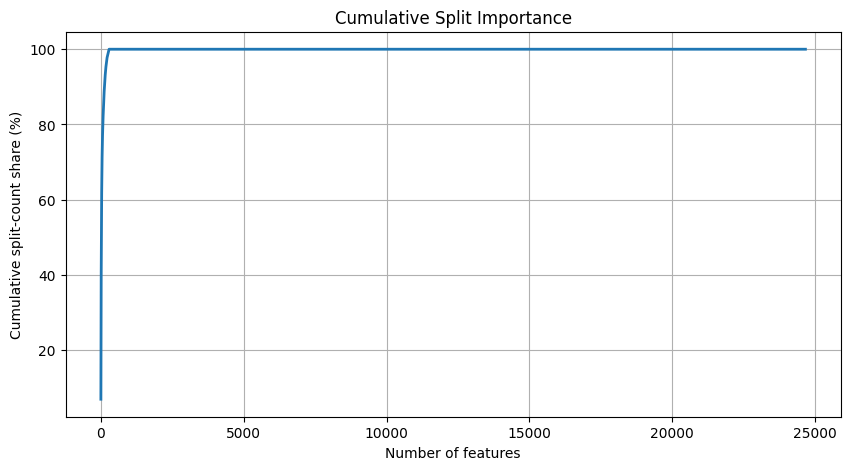

In [90]:
# ==========================================
# Experiment D2
# Feature Importance Distribution
# ==========================================


importance_dist = importance_df.copy()

importance_dist["Importance (%)"] = (
    importance_dist["Importance"]
    / importance_dist["Importance"].sum()
    * 100
)

importance_dist["Cumulative (%)"] = (
    importance_dist["Importance (%)"].cumsum()
)

print(f"Top 10 features split-count share: {importance_dist.iloc[:10]['Importance (%)'].sum():.2f}%")
print(f"Top 20 features split-count share: {importance_dist.iloc[:20]['Importance (%)'].sum():.2f}%")
print(f"Top 50 features split-count share: {importance_dist.iloc[:50]['Importance (%)'].sum():.2f}%")

plt.figure(figsize=(10,5))
plt.plot(
    range(1, len(importance_dist)+1),
    importance_dist["Cumulative (%)"],
    linewidth=2
)

plt.xlabel("Number of features")
plt.ylabel("Cumulative split-count share (%)")
plt.title("Cumulative Split Importance")
plt.grid(True)

plt.show()


### Interpretation

Cumulative split counts show how much of the model's splitting activity is concentrated in the top 10, 20 and 50 encoded features. One-hot categories are counted separately. These shares do not represent explained predictive quality.

The fit on all labeled data gave shares of 35.50%, **50.10%** and 71.47%, respectively. The training-split fit supports interpretation without fitting on validation labels; its ranking can differ.

## Experiment D3 — Correlation of Frequently Used Numerical Features

Inspect the top 20 numerical features by training-only split importance for overlapping information. Correlation does not establish redundancy or a causal relationship, and split counts do not measure a feature's isolated contribution to accuracy.


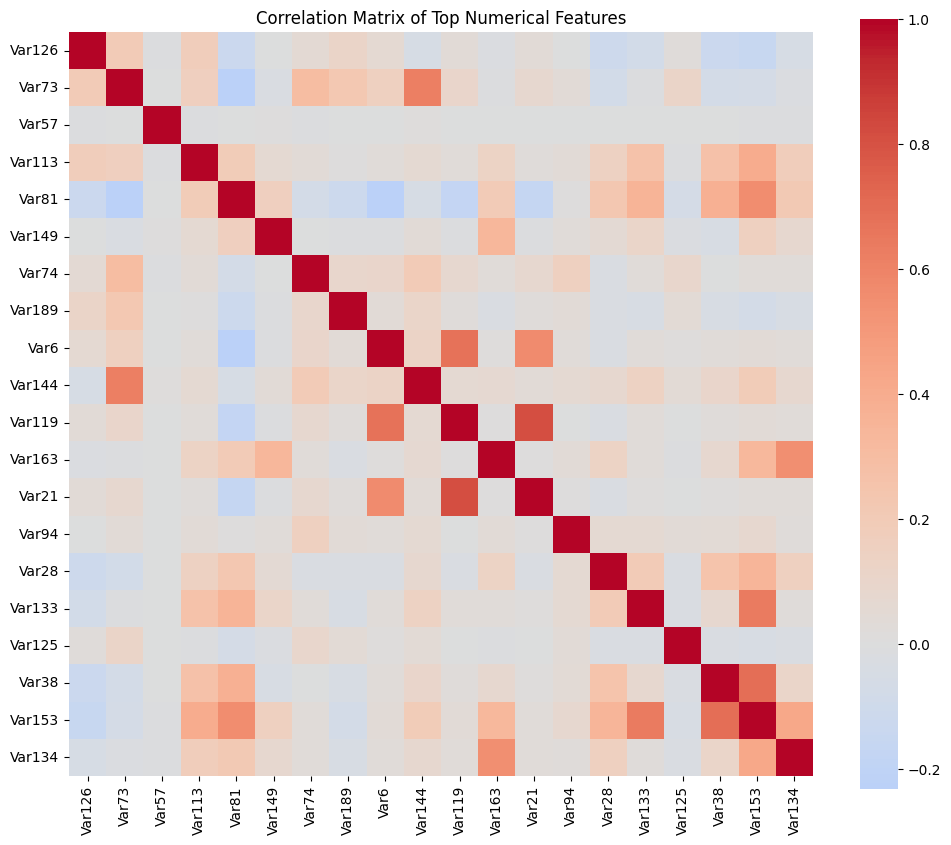

In [91]:
# ==========================================
# Experiment D3
# Correlation analysis of the most important
# numerical features
# ==========================================


# Top numerical features only
top_num = (
    importance_df[importance_df["Feature"].str.startswith("num__")]
    .head(20)["RawFeature"]
    .tolist()
)

corr = X_train[top_num].corr()

plt.figure(figsize=(12,10))

sns.heatmap(
    corr,
    cmap="coolwarm",
    center=0,
    square=True
)

plt.title("Correlation Matrix of Top Numerical Features")

plt.show()


In [92]:
# Correlation pairs among the top numerical features

corr_pairs = (
    corr.where(~corr.isna())
        .stack()
        .reset_index()
)

corr_pairs.columns = ["Feature 1", "Feature 2", "Correlation"]

# Remove self-correlations
corr_pairs = corr_pairs[corr_pairs["Feature 1"] != corr_pairs["Feature 2"]]

# Remove duplicate pairs
corr_pairs["Pair"] = corr_pairs.apply(
    lambda x: tuple(sorted([x["Feature 1"], x["Feature 2"]])),
    axis=1
)
corr_pairs = corr_pairs.drop_duplicates("Pair").drop(columns="Pair")

corr_pairs["Abs Corr"] = corr_pairs["Correlation"].abs()

corr_pairs.sort_values("Abs Corr", ascending=False).head(20)


,Feature 1,Feature 2,Correlation,Abs Corr
212,Var119,Var21,0.813744,0.813744
358,Var38,Var153,0.690915,0.690915
170,Var6,Var119,0.673768,0.673768
318,Var133,Var153,0.638735,0.638735
29,Var73,Var144,0.616174,0.616174
172,Var6,Var21,0.567442,0.567442
98,Var81,Var153,0.561046,0.561046
239,Var163,Var134,0.552137,0.552137
379,Var153,Var134,0.423044,0.423044
78,Var113,Var153,0.403996,0.403996


## Experiment D4 — Error Analysis

**Hypothesis**

The model may consistently misclassify a specific group of observations.

By analysing false positives and false negatives, we may identify hidden patterns that suggest new feature engineering opportunities or reveal weaknesses in the current preprocessing pipeline.

In [93]:
# ==========================================
# Experiment D4
# Error Analysis
# ==========================================

# Train only on the training split
error_model = clone(reduced_model)
error_model.fit(X_train_reduced, y_train)

# Predict on validation
y_pred_error = error_model.predict(X_valid_reduced)

cm = confusion_matrix(y_valid, y_pred_error)
print(cm)

error_df = X_valid.copy()
error_df["Actual"] = y_valid.values
error_df["Prediction"] = y_pred_error

error_df["Error"] = "Correct"
error_df.loc[
    (error_df["Actual"] == 1) &
    (error_df["Prediction"] == 0),
    "Error"
] = "False Negative"

error_df.loc[
    (error_df["Actual"] == 0) &
    (error_df["Prediction"] == 1),
    "Error"
] = "False Positive"

error_df["Error"].value_counts()


[[1592  147]
 [  49  212]]


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


,count
Error,
Correct,1804
False Positive,147
False Negative,49


In [94]:
error_df[
    error_df["Error"] != "Correct"
].head(20)

,Var1,Var2,Var3,Var4,Var5,Var6,Var7,Var9,Var10,Var11,...,Var223,Var224,Var225,Var226,Var227,Var228,Var229,Actual,Prediction,Error
3210,8.0,NaN,NaN,NaN,NaN,NaN,NaN,6.0,NaN,NaN,...,NaN,NaN,NaN,szEZ,RAYp,F2FyR07IdsN7I,NaN,0,1,False Positive
9601,NaN,NaN,NaN,NaN,NaN,1022.0,7.0,NaN,NaN,NaN,...,LM8l689qOp,NaN,ELof,rgKb,RAYp,F2FyR07IdsN7I,am7c,0,1,False Positive
2363,NaN,NaN,NaN,NaN,NaN,693.0,7.0,NaN,NaN,NaN,...,LM8l689qOp,NaN,kG3k,3Cy4,RAYp,F2FcTt7IdMT_v,mj86,0,1,False Positive
3973,NaN,NaN,NaN,NaN,NaN,658.0,0.0,NaN,NaN,NaN,...,LM8l689qOp,NaN,NaN,FSa2,RAYp,F2FyR07IdsN7I,NaN,0,1,False Positive
1886,NaN,NaN,NaN,NaN,0.0,NaN,NaN,NaN,0.0,NaN,...,LM8l689qOp,NaN,NaN,5Acm,RAYp,F2FyR07IdsN7I,NaN,0,1,False Positive
4236,0.0,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,NaN,...,NaN,NaN,NaN,Aoh3,ZI9m,F2FyR07IdsN7I,NaN,1,0,False Negative
5652,NaN,NaN,NaN,NaN,NaN,630.0,0.0,NaN,NaN,NaN,...,LM8l689qOp,NaN,NaN,Qu4f,RAYp,F2FyR07IdsN7I,NaN,0,1,False Positive
2244,NaN,NaN,NaN,NaN,NaN,441.0,7.0,NaN,NaN,NaN,...,LM8l689qOp,NaN,NaN,FSa2,RAYp,F2FyR07IdsN7I,NaN,0,1,False Positive
8153,NaN,NaN,NaN,NaN,NaN,973.0,14.0,NaN,NaN,NaN,...,LM8l689qOp,NaN,kG3k,PM2D,RAYp,F2FyR07IdsN7I,mj86,0,1,False Positive
888,NaN,NaN,NaN,NaN,NaN,546.0,0.0,NaN,NaN,NaN,...,LM8l689qOp,NaN,NaN,Qu4f,RAYp,F2FyR07IdsN7I,NaN,1,0,False Negative


In [95]:
print("False Negatives")
display(
    error_df[
        error_df["Error"] == "False Negative"
    ].describe(include="all")
)

print("False Positives")
display(
    error_df[
        error_df["Error"] == "False Positive"
    ].describe(include="all")
)

False Negatives


,Var1,Var2,Var3,Var4,Var5,Var6,Var7,Var9,Var10,Var11,...,Var223,Var224,Var225,Var226,Var227,Var228,Var229,Actual,Prediction,Error
count,1.0,0.0,0.0,2.0,3.000000e+00,43.000000,42.000000,1.0,3.000000,0.0,...,43,0,13,49,49,49,12,49.0,49.0,49
unique,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,3,0,3,19,4,5,2,NaN,NaN,1
top,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,LM8l689qOp,NaN,ELof,Qu4f,RAYp,F2FyR07IdsN7I,am7c,NaN,NaN,False Negative
freq,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,40,NaN,8,8,40,43,7,NaN,NaN,49
mean,0.0,NaN,NaN,0.0,8.196483e+05,1299.395349,4.166667,0.0,789.000000,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0,0.0,NaN
std,NaN,NaN,NaN,0.0,1.413891e+06,1947.328098,3.805751,NaN,1366.588087,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0,NaN
min,0.0,NaN,NaN,0.0,0.000000e+00,0.000000,0.000000,0.0,0.000000,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0,0.0,NaN
25%,0.0,NaN,NaN,0.0,3.340000e+03,290.500000,0.000000,0.0,0.000000,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0,0.0,NaN
50%,0.0,NaN,NaN,0.0,6.680000e+03,812.000000,7.000000,0.0,0.000000,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0,0.0,NaN
75%,0.0,NaN,NaN,0.0,1.229472e+06,1116.500000,7.000000,0.0,1183.500000,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0,0.0,NaN


False Positives


,Var1,Var2,Var3,Var4,Var5,Var6,Var7,Var9,Var10,Var11,...,Var223,Var224,Var225,Var226,Var227,Var228,Var229,Actual,Prediction,Error
count,1.0,1.0,1.0,4.0,7.0,129.000000,133.000000,1.0,7.000000e+00,1.0,...,123,1,33,147,147,147,27,147.0,147.0,147
unique,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,4,1,3,23,4,6,2,NaN,NaN,1
top,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,LM8l689qOp,4n2X,ELof,szEZ,RAYp,F2FyR07IdsN7I,mj86,NaN,NaN,False Positive
freq,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,106,1,16,15,137,137,15,NaN,NaN,147
mean,8.0,0.0,969.0,0.0,0.0,1053.147287,4.368421,6.0,9.135437e+05,8.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,1.0,NaN
std,NaN,NaN,NaN,0.0,0.0,1789.310382,5.068431,NaN,2.417009e+06,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0,NaN
min,8.0,0.0,969.0,0.0,0.0,35.000000,0.000000,6.0,0.000000e+00,8.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,1.0,NaN
25%,8.0,0.0,969.0,0.0,0.0,399.000000,0.000000,6.0,0.000000e+00,8.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,1.0,NaN
50%,8.0,0.0,969.0,0.0,0.0,728.000000,7.000000,6.0,0.000000e+00,8.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,1.0,NaN
75%,8.0,0.0,969.0,0.0,0.0,1071.000000,7.000000,6.0,0.000000e+00,8.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,1.0,NaN


In [96]:
# Compare errors within the same actual class and normalize by training IQR.
top_num_features = (
    importance_df[importance_df["Feature"].str.startswith("num__")]
    .head(15)["RawFeature"].tolist()
)

def compare_error_group(actual_class, error_name):
    rows = []
    for feature in top_num_features:
        correct = error_df.loc[
            (error_df["Actual"] == actual_class)
            & (error_df["Error"] == "Correct"), feature
        ]
        wrong = error_df.loc[error_df["Error"] == error_name, feature]
        train_values = X_train[feature]
        iqr = train_values.quantile(0.75) - train_values.quantile(0.25)
        shift = wrong.median() - correct.median()
        rows.append({
            "Feature": feature,
            "Correct same-class median": correct.median(),
            "Error median": wrong.median(),
            "Median shift / training IQR": shift / iqr if iqr > 0 else np.nan,
            "Correct missing %": correct.isna().mean() * 100,
            "Error missing %": wrong.isna().mean() * 100,
            "Correct observed n": int(correct.notna().sum()),
            "Error observed n": int(wrong.notna().sum()),
        })
    result = pd.DataFrame(rows)
    return result.sort_values(
        "Median shift / training IQR", key=lambda s: s.abs(),
        ascending=False, na_position="last",
    )

comparison_df = compare_error_group(0, "False Positive")
print("False positives versus true negatives")
display(comparison_df)


False positives versus true negatives


,Feature,Correct same-class median,Error median,Median shift / training IQR,Correct missing %,Error missing %,Correct observed n,Error observed n
4,Var81,62585.100000,151720.800000,0.542782,10.113065,12.244898,1431,129
1,Var73,64.000000,30.000000,-0.414634,0.000000,0.000000,1592,147
7,Var189,282.000000,246.000000,-0.285714,57.474874,55.102041,677,66
13,Var94,47905.500000,24054.000000,-0.216978,43.341709,48.979592,902,75
6,Var74,21.000000,0.000000,-0.214286,10.113065,9.523810,1431,133
14,Var28,201.600000,220.080000,0.184211,9.233668,8.843537,1445,134
8,Var6,875.000000,728.000000,-0.157895,10.113065,12.244898,1431,129
3,Var113,31177.000000,81917.200000,0.154466,0.000000,0.000000,1592,147
5,Var149,46151.000000,90769.000000,0.119130,13.253769,13.605442,1381,127
12,Var21,144.000000,140.000000,-0.033333,10.113065,12.244898,1431,129


### Interpretation: False Positives

Compare false positives with true negatives, keeping the actual class fixed at 0. Median differences are divided by the training IQR to reduce the effect of different feature units. An undefined normalized shift indicates zero or unavailable IQR. These descriptive differences suggest hypotheses; they do not prove causes of errors. The validation confusion matrix contained 147 false positives and 49 false negatives.


In [97]:
comparison_fn_df = compare_error_group(1, "False Negative")
print("False negatives versus true positives")
display(comparison_fn_df)


False negatives versus true positives


,Feature,Correct same-class median,Error median,Median shift / training IQR,Correct missing %,Error missing %,Correct observed n,Error observed n
7,Var189,180.000000,270.000000,0.714286,58.490566,44.897959,88,27
13,Var94,43176.000000,77088.000000,0.308498,47.641509,53.061224,111,23
2,Var57,3.035783,3.966247,0.263141,0.000000,0.000000,212,49
4,Var81,131927.700000,90973.500000,-0.249386,5.188679,12.244898,201,43
5,Var149,80276.000000,0.000000,-0.214336,13.679245,20.408163,183,39
3,Var113,83345.200000,18608.400000,-0.197075,0.000000,0.000000,212,49
8,Var6,651.000000,812.000000,0.172932,5.188679,12.244898,201,43
11,Var163,133104.000000,63732.000000,-0.113138,4.245283,12.244898,203,43
14,Var28,230.560000,220.080000,-0.104466,4.245283,12.244898,203,43
10,Var119,540.000000,505.000000,-0.075269,5.188679,12.244898,201,43


### Interpretation: False Negatives

Compare false negatives with true positives, keeping the actual class fixed at 1. Interpret normalized shifts together with observed sample sizes and missing-value rates. This validation set has been explored repeatedly and is now development data, not an untouched test set.


## Experiment D5 — Targeted Feature Engineering

Feature-importance and validation-error analysis identified Var134, Var163, Var149, Var81, Var113 and Var125 as candidates for quartile flags. Selection used an all-data importance ranking and validation errors, so subsequent evaluation is exploratory rather than independent.

Each column receives a flag below Q25 and another above Q75. D5 uses **212 non-empty input columns plus 12 flags**, without separate missing indicators. Comparison with the missing-indicator model therefore changes more than the flags alone. D7 compares the flags using a matched feature set and evaluation protocol.

In [98]:
# ==========================================
# Experiment D5
# Targeted Feature Engineering
# ==========================================

X_train_d5 = X_train.copy()
X_valid_d5 = X_valid.copy()

candidate_features = [
    "Var134",
    "Var163",
    "Var149",
    "Var81",
    "Var113",
    "Var125"
]

for col in candidate_features:

    q75 = X_train[col].quantile(0.75)
    q25 = X_train[col].quantile(0.25)

    X_train_d5[f"{col}_high"] = (
        X_train[col] > q75
    ).astype(int)

    X_valid_d5[f"{col}_high"] = (
        X_valid[col] > q75
    ).astype(int)

    X_train_d5[f"{col}_low"] = (
        X_train[col] < q25
    ).astype(int)

    X_valid_d5[f"{col}_low"] = (
        X_valid[col] < q25
    ).astype(int)

print(
    X_train_d5.filter(regex="_high|_low").head()
)

      Var134_high  Var134_low  Var163_high  Var163_low  Var149_high  \
3776            0           0            0           0            0   
1114            1           0            0           0            1   
3705            0           1            0           0            0   
7286            1           0            1           0            1   
1658            0           0            0           0            0   

      Var149_low  Var81_high  Var81_low  Var113_high  Var113_low  Var125_high  \
3776           0           0          1            0           0            0   
1114           0           0          0            0           0            0   
3705           0           0          1            0           0            0   
7286           0           0          0            0           0            0   
1658           0           0          0            0           1            1   

      Var125_low  
3776           1  
1114           0  
3705           0  
7286      

### Development Evaluation

Fit D5 on the training split, with quartile boundaries learned from that split. Report metrics on the reused validation split. This is a development result and is not an isolated measurement of the 12 flags' benefit. The matched D7 comparison below provides a controlled comparison.


In [99]:
numeric_features_d5 = (
    X_train_d5
    .select_dtypes(include="number")
    .columns
    .tolist()
)

categorical_features_d5 = (
    X_train_d5
    .select_dtypes(include="object")
    .columns
    .tolist()
)

preprocessor_d5 = ColumnTransformer([
    ("num", clone(numeric_transformer), numeric_features_d5),
    ("cat", clone(categorical_transformer), categorical_features_d5)
])

model_d5 = Pipeline([
    ("preprocessor", preprocessor_d5),
    ("classifier", clone(reduced_model.named_steps["classifier"]))
])

model_d5.fit(X_train_d5, y_train)

y_pred_d5 = model_d5.predict(X_valid_d5)

print(f"Accuracy: {accuracy_score(y_valid, y_pred_d5):.4f}")
print(f"Balanced Accuracy: {balanced_accuracy_score(y_valid, y_pred_d5):.4f}")
print(f"Precision: {precision_score(y_valid, y_pred_d5):.4f}")
print(f"Recall: {recall_score(y_valid, y_pred_d5):.4f}")
print(f"F1-score: {f1_score(y_valid, y_pred_d5):.4f}")

Accuracy: 0.9060
Balanced Accuracy: 0.8678
Precision: 0.6034
Recall: 0.8161
F1-score: 0.6938


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


# Experiment D6 — Decision Threshold Optimization

## Hypothesis

The default classification threshold (0.5) may not provide the best balance between Precision and Recall.

By adjusting the probability threshold, we may improve the F1-score or Balanced Accuracy without retraining the model.

In [100]:
# Probabilities from the trained model
y_prob_d6 = model_d5.predict_proba(X_valid_d5)[:, 1]

thresholds_d6 = [0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60, 0.65, 0.70]

results_d6 = []

for t in thresholds_d6:
    y_pred_d6 = (y_prob_d6 >= t).astype(int)

    results_d6.append({
        "Threshold": t,
        "Accuracy": accuracy_score(y_valid, y_pred_d6),
        "Balanced Accuracy": balanced_accuracy_score(y_valid, y_pred_d6),
        "Precision": precision_score(y_valid, y_pred_d6),
        "Recall": recall_score(y_valid, y_pred_d6),
        "F1": f1_score(y_valid, y_pred_d6)
    })

threshold_results_d6 = pd.DataFrame(results_d6)
threshold_results_d6


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


,Threshold,Accuracy,Balanced Accuracy,Precision,Recall,F1
0,0.30,0.8755,0.879562,0.513333,0.885057,0.649789
1,0.35,0.8810,0.872955,0.526932,0.862069,0.654070
2,0.40,0.8910,0.873821,0.553616,0.850575,0.670695
3,0.45,0.8995,0.875452,0.578947,0.842912,0.686427
4,0.50,0.9060,0.867793,0.603399,0.816092,0.693811
5,0.55,0.9100,0.852183,0.625387,0.773946,0.691781
6,0.60,0.9145,0.843373,0.650000,0.747126,0.695187
7,0.65,0.9195,0.825082,0.689394,0.697318,0.693333
8,0.70,0.9245,0.818188,0.727273,0.674330,0.699801


In [101]:
display(threshold_results_d6.sort_values("Balanced Accuracy", ascending=False))


,Threshold,Accuracy,Balanced Accuracy,Precision,Recall,F1
0,0.30,0.8755,0.879562,0.513333,0.885057,0.649789
3,0.45,0.8995,0.875452,0.578947,0.842912,0.686427
2,0.40,0.8910,0.873821,0.553616,0.850575,0.670695
1,0.35,0.8810,0.872955,0.526932,0.862069,0.654070
4,0.50,0.9060,0.867793,0.603399,0.816092,0.693811
5,0.55,0.9100,0.852183,0.625387,0.773946,0.691781
6,0.60,0.9145,0.843373,0.650000,0.747126,0.695187
7,0.65,0.9195,0.825082,0.689394,0.697318,0.693333
8,0.70,0.9245,0.818188,0.727273,0.674330,0.699801


### Result and Limitations

For D5, threshold 0.30 increased validation Balanced Accuracy from **0.8678 to 0.8796**. It gave the highest BA among tested thresholds 0.30–0.70. Selection used the repeatedly examined local validation set, not OOF predictions; precision and F1 are secondary diagnostics.

The final threshold is **0.30**. Quartiles are estimated from all labeled data for final training, without using the submission data.

In [102]:
# ==========================================
# FINAL MODEL + KAGGLE SUBMISSION
# D5 engineered features + threshold 0.30
# ==========================================


FINAL_THRESHOLD = 0.30

candidate_features = [
    "Var134",
    "Var163",
    "Var149",
    "Var81",
    "Var113",
    "Var125"
]

# --------------------------------------------------
# 1. Combine train + validation back into full train
# --------------------------------------------------

X_full_d5 = pd.concat([X_train, X_valid]).copy()
y_full_d5 = pd.concat([y_train, y_valid])

# Test must contain the same original features
test_d5 = test.loc[:, X_train.columns].copy()

# --------------------------------------------------
# 2. Create D5 engineered features
#    Thresholds are learned from the full labeled set
# --------------------------------------------------

for col in candidate_features:

    q25 = X_full_d5[col].quantile(0.25)
    q75 = X_full_d5[col].quantile(0.75)

    X_full_d5[f"{col}_low"] = (
        X_full_d5[col] < q25
    ).astype(int)

    X_full_d5[f"{col}_high"] = (
        X_full_d5[col] > q75
    ).astype(int)

    test_d5[f"{col}_low"] = (
        test_d5[col] < q25
    ).astype(int)

    test_d5[f"{col}_high"] = (
        test_d5[col] > q75
    ).astype(int)

# Safety checks
assert X_full_d5.columns.equals(test_d5.columns)
assert len(X_full_d5) == len(y_full_d5)

# --------------------------------------------------
# 3. Train final D5 model on ALL labeled data
# --------------------------------------------------

final_model_d5 = clone(model_d5)
final_model_d5.fit(X_full_d5, y_full_d5)

# --------------------------------------------------
# 4. Predict probabilities + threshold 0.30
# --------------------------------------------------

test_prob_d5 = final_model_d5.predict_proba(test_d5)[:, 1]

test_pred_d5 = (
    test_prob_d5 >= FINAL_THRESHOLD
).astype(int)

# --------------------------------------------------
# 5. Create Kaggle submission
# --------------------------------------------------

submission_final = sample_submission.copy()
submission_final["y"] = test_pred_d5

filename = "submission_final_d5_threshold_030.csv"

submission_final.to_csv(filename, index=False)

print("Final train shape:", X_full_d5.shape)
print("Final test shape:", test_d5.shape)
print("Threshold:", FINAL_THRESHOLD)
print("\nPrediction distribution:")
print(submission_final["y"].value_counts())
print("\nSubmission preview:")
display(submission_final.head())

# Download CSV
files.download(filename)

Final train shape: (10000, 224)
Final test shape: (2500, 224)
Threshold: 0.3

Prediction distribution:
y
0    1915
1     585
Name: count, dtype: int64

Submission preview:


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


,index,y
0,0,0
1,1,0
2,2,0
3,3,0
4,4,0


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## D5 Submission Verification

The SHA-256 check compares the ordered CSV predictions against a local reference associated with the reported Public Score of **0.8977**. It confirms prediction consistency. The reference has not been independently compared with Kaggle's stored upload, and the check does not provide an independent performance estimate.

In [108]:
verified_d5 = pd.read_csv("submission_final_d5_threshold_030.csv")
assert verified_d5.columns.tolist() == ["index", "y"]
assert len(verified_d5) == len(sample_submission) == 2500
assert verified_d5["index"].equals(sample_submission["index"])
assert verified_d5["index"].is_unique
assert not verified_d5.isna().any().any()
assert set(verified_d5["y"].unique()).issubset({0, 1})
canonical_d5 = verified_d5.to_csv(index=False, lineterminator="\n")
fingerprint_d5 = hashlib.sha256(canonical_d5.encode("utf-8")).hexdigest()
print("D5 SHA-256:", fingerprint_d5)
assert fingerprint_d5 == "713248f66449593af70fee0c5dd3d8f06b680a07fd2aadf81cefa2af943bffbf", (
    "D5 predictions differ from the local reference. Check data, versions, "
    "feature order, parameters and execution order; do not edit predictions."
)
print("D5 PASS: predictions successfully verified.")


D5 SHA-256: 713248f66449593af70fee0c5dd3d8f06b680a07fd2aadf81cefa2af943bffbf
D5 PASS: predictions successfully verified.


## Experiment D7 — Matched Comparison of Quartile Flags

Compare balanced LightGBM on the same 212 original columns with and without the 12 D5 flags. Both variants use identical classifier settings, imputers, categorical encoding and five stratified folds. No separate missing indicators or correlated-column removal are added.

Quartile boundaries are fitted inside each training fold through a Pipeline transformer. The primary comparison uses the already fixed threshold **0.30** for both models. Threshold 0.50 and the best threshold on a fixed OOF grid are secondary diagnostics. The threshold-optimized score is a development estimate.

This controls the immediate feature change, but it does not undo prior exploration of the data when selecting the six columns and threshold. It is not a new untouched evaluation. This experiment and its export do not automatically replace the selected Kaggle submission.


### Matched Cross-Validation Results

| Matched variant | OOF BA at fixed 0.30 | Best OOF BA on diagnostic grid | Diagnostic threshold |
|---|---:|---:|---:|
| Original 212 columns | 0.8817 | 0.8868 | 0.22 |
| Original columns + 12 flags | 0.8812 | 0.8863 | 0.22 |

At threshold 0.30, the flags changed pooled OOF Balanced Accuracy by **−0.0005** and improved 2 of 5 folds. This protocol did not establish an improvement from the flags. Scores maximized over the threshold grid are development estimates.

The D5 reference check matched all **2,500 ordered predictions** with zero differences. Prediction consistency and public leaderboard performance are separate checks.

In [104]:
class D7QuartileFlags(BaseEstimator, TransformerMixin):
    def __init__(self, columns):
        self.columns = columns

    def fit(self, X, y=None):
        self.q25_ = X.loc[:, self.columns].quantile(0.25)
        self.q75_ = X.loc[:, self.columns].quantile(0.75)
        return self

    def transform(self, X):
        check_is_fitted(self, ["q25_", "q75_"])
        result = X.copy()
        for col in self.columns:
            # Match D5: missing raw values produce two zero flags.
            result[f"{col}_high"] = (X[col] > self.q75_[col]).astype(int)
            result[f"{col}_low"] = (X[col] < self.q25_[col]).astype(int)
        return result

D7_FEATURES = ("Var134", "Var163", "Var149", "Var81", "Var113", "Var125")
D7_THRESHOLD = 0.30
D7_BASE_COLUMNS = X_train.columns.tolist()
X_d7 = X.loc[:, D7_BASE_COLUMNS].copy()
y_d7 = y.copy()
test_d7 = test.loc[:, D7_BASE_COLUMNS].copy()
assert X_d7.index.equals(y_d7.index)
assert X_d7.columns.equals(test_d7.columns)
assert "y" not in X_d7.columns
assert set(D7_FEATURES).issubset(X_d7.columns)

# Match the exact numeric-column order used by model_d5.
d7_num = X_d7.select_dtypes(include="number").columns.tolist()
d7_cat = X_d7.select_dtypes(include="object").columns.tolist()
d7_flags = [f"{col}_{suffix}" for col in D7_FEATURES for suffix in ("high", "low")]
assert not set(d7_flags).intersection(X_d7.columns)

def make_d7_model(with_flags):
    numeric_columns = d7_num + (d7_flags if with_flags else [])
    preprocessing = ColumnTransformer([
        ("num", clone(numeric_transformer), numeric_columns),
        ("cat", clone(categorical_transformer), d7_cat),
    ])
    steps = []
    if with_flags:
        steps.append(("quartile_flags", D7QuartileFlags(D7_FEATURES)))
    steps.extend([
        ("preprocessor", preprocessing),
        ("classifier", clone(model_d5.named_steps["classifier"])
         .set_params(n_jobs=1)),
    ])
    return Pipeline(steps)

d7_models = {
    "Original columns": make_d7_model(False),
    "Original columns + 12 flags": make_d7_model(True),
}
print("Original columns:", len(D7_BASE_COLUMNS))
print("Added flags:", len(d7_flags))


Original columns: 212
Added flags: 12


In [105]:
# Ten fits: five for each model. Keep folds and fixed threshold identical.
d7_folds = list(StratifiedKFold(
    n_splits=5, shuffle=True, random_state=42
).split(X_d7, y_d7))
d7_grid = np.round(np.arange(0.05, 0.96, 0.01), 2)
d7_oof = {}
d7_rows = []
d7_fold_rows = []
d7_selected_thresholds = {}

for name, estimator in d7_models.items():
    print("Evaluating:", name, flush=True)
    probabilities = cross_val_predict(
        clone(estimator), X_d7, y_d7, cv=d7_folds,
        method="predict_proba", n_jobs=1,
    )[:, 1]
    assert np.isfinite(probabilities).all()
    d7_oof[name] = probabilities
    fixed_predictions = (probabilities >= D7_THRESHOLD).astype(int)
    fold_scores = []
    for fold_id, (_, valid_positions) in enumerate(d7_folds, 1):
        score = balanced_accuracy_score(
            y_d7.iloc[valid_positions], fixed_predictions[valid_positions]
        )
        fold_scores.append(score)
        d7_fold_rows.append({"Model": name, "Fold": fold_id, "BA at 0.30": score})
    grid_scores = np.array([
        balanced_accuracy_score(y_d7, (probabilities >= t).astype(int))
        for t in d7_grid
    ])
    best_position = int(np.argmax(grid_scores))
    d7_selected_thresholds[name] = float(d7_grid[best_position])
    d7_rows.append({
        "Model": name,
        "OOF BA at 0.30": balanced_accuracy_score(y_d7, fixed_predictions),
        "Fold mean BA at 0.30": np.mean(fold_scores),
        "Fold SD at 0.30": np.std(fold_scores, ddof=1),
        "OOF BA at 0.50": balanced_accuracy_score(y_d7, (probabilities >= 0.5).astype(int)),
        "OOF-selected threshold (diagnostic)": float(d7_grid[best_position]),
        "Best OOF BA (diagnostic)": float(grid_scores[best_position]),
    })

d7_comparison = pd.DataFrame(d7_rows).set_index("Model")
display(d7_comparison.round(4))
d7_fold_comparison = pd.DataFrame(d7_fold_rows).pivot(
    index="Fold", columns="Model", values="BA at 0.30"
)
d7_fold_comparison["Flags minus original"] = (
    d7_fold_comparison["Original columns + 12 flags"]
    - d7_fold_comparison["Original columns"]
)
display(d7_fold_comparison.round(4))
d7_delta = (
    d7_comparison.loc["Original columns + 12 flags", "OOF BA at 0.30"]
    - d7_comparison.loc["Original columns", "OOF BA at 0.30"]
)
print(f"Matched OOF difference at fixed 0.30: {d7_delta:+.4f}")
print("Folds with positive difference:", int((d7_fold_comparison["Flags minus original"] > 0).sum()), "/ 5")
print("Fold SD is descriptive, not a confidence interval.")


Evaluating: Original columns


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


Evaluating: Original columns + 12 flags


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/ut

,OOF BA at 0.30,Fold mean BA at 0.30,Fold SD at 0.30,OOF BA at 0.50,OOF-selected threshold (diagnostic),Best OOF BA (diagnostic)
Model,,,,,,
Original columns,0.8817,0.8817,0.0134,0.8615,0.22,0.8868
Original columns + 12 flags,0.8812,0.8812,0.0124,0.8634,0.22,0.8863


Model,Original columns,Original columns + 12 flags,Flags minus original
Fold,,,
1,0.8990,0.8944,-0.0046
2,0.8691,0.8694,0.0003
3,0.8796,0.8796,0.0000
4,0.8916,0.8934,0.0018
5,0.8690,0.8690,0.0000


Matched OOF difference at fixed 0.30: -0.0005
Folds with positive difference: 2 / 5
Fold SD is descriptive, not a confidence interval.


In [106]:
# Report only computed results; do not invent a Kaggle score.
from IPython.display import Markdown, display
if d7_delta > 0:
    d7_finding = "The flags improved the pooled development OOF score at the fixed threshold."
elif d7_delta < 0:
    d7_finding = "The flags reduced the pooled development OOF score at the fixed threshold."
else:
    d7_finding = "The pooled development OOF score was unchanged at the fixed threshold."
display(Markdown(
    "### D7 Result\n\n" + d7_finding
    + f" Difference: **{d7_delta:+.4f}**. "
    + "The same original columns, folds, classifier and threshold were used. "
    + "This is a controlled development comparison, not independent proof of generalization. "
    + "The current confirmed public best remains D5 at **0.8977**."
))


### D7 Result

The flags reduced the pooled development OOF score at the fixed threshold. Difference: **-0.0005**. The same original columns, folds, classifier and threshold were used. This is a controlled development comparison, not independent proof of generalization. The current confirmed public best remains D5 at **0.8977**.

### D7 Comparison Submission

The variant with the higher pooled OOF Balanced Accuracy at threshold 0.30 is fitted on all labeled data; ties favor the model without flags. Predictions use the fixed threshold and a separate filename. Quartiles, when used, are estimated during fitting.

D7 uses a different training-row order from D5, so its predictions may differ. **D5 remains the selected final submission.**

In [107]:
d7_export_name = (
    "Original columns + 12 flags" if d7_delta > 0 else "Original columns"
)
final_model_d7 = clone(d7_models[d7_export_name])
final_model_d7.fit(X_d7, y_d7)
d7_test_probabilities = final_model_d7.predict_proba(test_d7)[:, 1]
assert np.isfinite(d7_test_probabilities).all()
submission_d7 = sample_submission.copy()
submission_d7["y"] = (d7_test_probabilities >= D7_THRESHOLD).astype(int)
assert submission_d7.columns.tolist() == ["index", "y"]
assert len(submission_d7) == len(test_d7) == 2500
assert submission_d7["index"].equals(sample_submission["index"])
assert submission_d7["index"].is_unique
assert not submission_d7.isna().any().any()
assert set(submission_d7["y"].unique()).issubset({0, 1})
d7_export_suffix = "flags" if d7_delta > 0 else "original"
filename_d7 = f"submission_d7_{d7_export_suffix}_threshold_030.csv"
submission_d7.to_csv(filename_d7, index=False)
print("Exported variant:", d7_export_name)
print("Threshold:", D7_THRESHOLD)
print("File:", filename_d7)
print(submission_d7["y"].value_counts())
#files.download(filename_d7)


Exported variant: Original columns
Threshold: 0.3
File: submission_d7_original_threshold_030.csv
y
0    1922
1     578
Name: count, dtype: int64


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Final Conclusion

The project evaluated customer churn prediction using Balanced Accuracy to account for class imbalance. The selected D5 submission, **`submission_final_d5_threshold_030.csv`**, achieved a Kaggle Public Score of **0.8977**, compared with **0.8950** for the missing-indicator model.

The work covered:

- **Data exploration and preprocessing:** missingness, feature types, categorical cardinality, target distribution and correlations; removal of empty columns; numerical and categorical imputation; one-hot encoding and scaling where appropriate.
- **Model comparison:** logistic regression and several ensemble classifiers. LightGBM achieved the strongest initial validation Balanced Accuracy, **0.7929**.
- **Class balancing and tuning:** SMOTE, class weighting, RandomizedSearchCV and Optuna. Class weighting increased validation BA to **0.8593**; tuned weighted models scored **0.8912** and **0.8927** on validation.
- **Alternative representations:** dimensionality reduction, removal of sparse or correlated columns, probability averaging, missing counts, missing indicators and correlation-based feature recovery. Their effects differed between local evaluation and the public leaderboard.
- **Feature analysis:** split importance, its concentration across features, correlations among frequently used columns, and false-positive and false-negative analysis.
- **Targeted feature engineering:** quartile flags for Var134, Var163, Var149, Var81, Var113 and Var125, followed by threshold evaluation and a matched cross-validation comparison.

D5 combines balanced LightGBM, median numerical imputation, categorical imputation and one-hot encoding. It uses **212 non-empty input columns and 12 quartile flags**, without removing the 13 correlated columns or adding separate missing indicators. The model is fitted on **10,000 labeled customers** and produces **2,500 predictions**, including **585 positive labels**.

The decision threshold is **0.30**, selected from the tested local-validation thresholds. D5 validation Balanced Accuracy is **0.8678** at 0.50 and **0.8796** at 0.30. Quartiles are fitted on training data during evaluation and on all labeled data for the final fit.

The public-score gain does not isolate the effect of the flags because the input columns and missing-indicator configuration also differ from the missing-indicator model. In the matched D7 comparison, OOF BA at 0.30 was **0.8817 without flags** and **0.8812 with flags**, a difference of **−0.0005**. This comparison did not establish a standalone benefit from the flags.

Repeated feature exploration, tuning and validation reuse limit the independence of these estimates. Fitting transformations within folds avoids fitting their parameters on held-out rows, but does not undo feature-selection decisions made using the dataset. Validation, OOF and public leaderboard scores reflect different evaluation procedures; performance on other unseen data is not guaranteed.